# TP2 – Representación vectorial de texto: embeddings y búsqueda semántica
**UNR · TUIA · Procesamiento de Lenguaje Natural – Unidad 2**

**Integrantes:** Franco Renna · Micaela Gómez · Irma Carolina Ruiz · Franco Esparza

**Cómo ejecutar este notebook**

*En local:* crear el entorno e instalar `requirements.txt` (ver `README.md`). Funciona tanto si se abre desde la raíz del repo como desde `src/`. La credencial de Supabase va en un archivo `.env` (plantilla en `.env.example`).

*En Colab:*
1. Abrir el panel **Secrets** (ícono de llave), crear el secreto `DATABASE_URL` con la cadena de conexión **Session pooler** de Supabase y habilitar el acceso para este notebook. Colab no tiene IPv6, así que la cadena de conexión directa no funciona ahí.
2. Ejecutar las celdas en orden. La primera instala lo que Colab no trae; la de carga pide subir `libros.csv`.

En los dos casos, el modelo pre-entrenado SBW (1,1 GB) se descarga solo la primera vez. Sin credencial de Supabase, las celdas que usan la base se omiten y el resto corre igual.

## Librerías utilizadas

In [64]:
# Detecta si el notebook corre en Google Colab: ahí hay que instalar lo que no viene preinstalado
import sys
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    # No se usa el pin numpy==1.23.5 del apunte (no convive con sentence-transformers): va gensim>=4.3.3 con el numpy de Colab
    %pip install -q "gensim>=4.3.3" psycopg2-binary python-dotenv
# En local las dependencias se instalan una sola vez con: pip install -r requirements.txt

import json
import os
import re
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import psycopg2

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer

# Semilla única para todo lo aleatorio del notebook (muestreos, Word2Vec)
SEMILLA = 42

In [65]:
# Carpeta raíz del proyecto: sirve si se ejecuta desde la raíz del repo, desde src/ o en Colab
if EN_COLAB:
    RAIZ = Path("/content")
elif (Path.cwd() / "data").exists():
    RAIZ = Path.cwd()
else:
    RAIZ = Path.cwd().parent

DIR_DATA = RAIZ / "data"        # CSV del TP1 y archivos generados por este notebook
DIR_MODELOS = RAIZ / "models"   # modelos pesados (carpeta ignorada por git)
DIR_DATA.mkdir(exist_ok=True)
DIR_MODELOS.mkdir(exist_ok=True)

In [66]:
# Recursos de NLTK: lista de stopwords y modelos del tokenizador (quiet=True evita mensajes que dependen de cada máquina)
for recurso in ["stopwords", "punkt", "punkt_tab"]:
    nltk.download(recurso, quiet=True)

## Parte A - Preparación del corpus

### Extracción del archivo csv del TP parte 1

In [67]:
# Ruta del csv extraído en el TP1
archivo_csv = DIR_DATA / "libros.csv"

# En Colab el archivo no está (el repositorio es privado): se pide subirlo a mano
if not archivo_csv.exists() and EN_COLAB:
    from google.colab import files
    subido = files.upload()
    archivo_csv.write_bytes(next(iter(subido.values())))

# Lectura del csv con pandas
df_libros = pd.read_csv(archivo_csv, dtype=str, keep_default_na=False)
# dtype=str fuerza a todos los campos a ser leídos como string,
# keep_default_na=False evita que se reemplacen los valores vacíos por NaN

print("Libros leídos:", len(df_libros))

Libros leídos: 150


Se realiza una copia del archivo csv para no modificar el original

In [68]:
df_sinopsis = df_libros[df_libros["sinopsis"].str.strip() != ""].copy()
#Me quedo solo con los libros que tienen sinopsis y elimino los espacios de al principio y final de la sinopsis
#df_sinopsis

### Autores y género: de string a lista

En el csv los autores y generos se guardaron como un string de json. Es una lista guardada como string, se decidio convertirla a una lista de Python para poder visualizar cuantos libros comparten géneros simultáneamente, ya que todos de ante mano pertenecen al género ciencia-ficción que fue elegido en la parte 1 del tp. 

In [69]:
# autores y generos pasan de string JSON a lista de Python; después se cuenta en cuántos libros aparece cada género
df_sinopsis["autores"] = df_sinopsis["autores"].apply(json.loads)
df_sinopsis["generos"] = df_sinopsis["generos"].apply(json.loads)

print(df_sinopsis["generos"].explode().value_counts())
print("Géneros por libro (promedio):", df_sinopsis["generos"].apply(len).mean())

generos
Ciencia ficción               150
Novela                        109
Relato                         24
Fantástico                     21
Aventuras                      10
Juvenil                         5
Terror                          4
Intriga                         4
Otros                           4
Infantil y juvenil              3
Histórico                       2
Crítica y teoría literaria      2
Ensayo                          2
Publicaciónes periódicas        2
Romántico                       2
Infantil                        2
Bélico                          1
Poesía                          1
Cuentos                         1
Humor                           1
Ucronía                         1
Erótico                         1
Distopía                        1
Filosófico                      1
Name: count, dtype: int64
Géneros por libro (promedio): 2.36


### Normalización y limpieza

### Dos versiones de texto: Uno crudo y otro limpio

Texto crudo: sinopsis_emb
Texto limpio: sinopsis_limpio

In [70]:
df_sinopsis["sinopsis_emb"] = df_sinopsis["sinopsis"].apply(
    lambda x: re.sub(r"\s+", " ", x).strip()
)

#Normalizo los espacios en blanco de la sinopsis, reemplazando multiples espacios por uno solo y eliminando los espacios al principio y final de la sinopsis

In [71]:
# Carga las palabras stopwords en español
stop_words_es = set(stopwords.words("spanish"))

In [72]:
def limpiar_texto(texto: str) -> str:
    t = texto.lower()  # Pasa a minúscula
    t = re.sub(
        r"[^\w\s]", " ", t
    )  # Quita la puntuación y caracteres especiales
    tokens = word_tokenize(t)  # Tokenización
    filtrados = [
        w
        for w in tokens
        if w not in stop_words_es and len(w) > 1 and not w.isdigit()
    ]  # Stopwords y palabras de un solo caracter y números
    return " ".join(filtrados)


df_sinopsis["sinopsis_limpio"] = df_sinopsis["sinopsis_emb"].apply(limpiar_texto)

Guarda la nueva información en un archivo csv 

In [73]:
# Definimos la ruta
ruta_guardado = DIR_DATA / "libros_preprocesados.csv"

# autores y generos son listas de Python: se vuelven a guardar como array JSON (igual que en libros.csv),
# para que quien lea este CSV pueda recuperarlas con json.loads
df_guardar = df_sinopsis.copy()
for columna in ["autores", "generos"]:
    df_guardar[columna] = df_guardar[columna].apply(lambda lista: json.dumps(lista, ensure_ascii=False))

# Guardamos el DataFrame en formato CSV
df_guardar.to_csv(ruta_guardado, index=False, encoding="utf-8")

print("Dataset preprocesado guardado en: data/libros_preprocesados.csv")

Dataset preprocesado guardado en: data/libros_preprocesados.csv


### Decisión de preprocesamiento

Se mantienen dos versiones de las sinopsis. `sinopsis_limpio` (minúsculas, sin puntuación, sin stopwords, sin números) se usa para TF-IDF. `sinopsis_emb` conserva el texto original y solo normaliza los espacios: es la entrada de SBERT. Aplicar a SBERT la limpieza de TF-IDF le quitaría las palabras funcionales y la puntuación con las que procesa cada oración.

Los acentos no se eliminan: se perdería la diferencia entre "sí"/"si" o "él"/"el", y el vocabulario del modelo pre-entrenado SBW tiene tildes. Word2Vec (Parte B) usa una tokenización propia, que conserva las stopwords y separa por oraciones.

## Primer análisis del corpus

Antes de entrenar modelos, se responden las cuatro preguntas que plantea el enunciado sobre el corpus.

*1. Con 12 documentos, TF-IDF es casi ruido. ¿Cuántas sinopsis harían falta para que los términos característicos sean estables? ¿Cómo lo medirían?*

La IDF de cada palabra depende de en cuántos documentos aparece; con pocos documentos, una sola sinopsis cambia mucho ese conteo.

Para medirlo se toman **dos muestras aleatorias independientes** de *n* sinopsis, se calculan los 20 términos con mayor TF-IDF promedio en cada una y se mide cuánto coinciden con el índice de Jaccard (términos en común / términos distintos en total). Se repite 30 veces para cada tamaño *n*. Si los términos característicos fueran estables, dos muestras distintas darían casi los mismos términos (Jaccard cercano a 1).

,mean,std
n,,
12,0.12,0.06
25,0.21,0.06
50,0.30,0.07
75,0.38,0.07
100,0.48,0.09
150,0.54,0.09


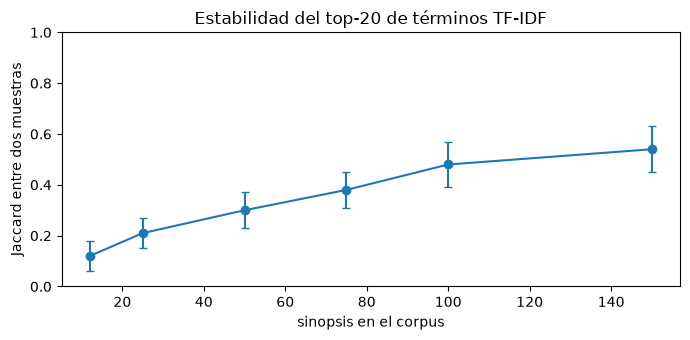

In [74]:
def top_terminos_tfidf(textos, k=20):
    # Los k términos con mayor peso TF-IDF promedio entre los documentos dados
    vectorizador = TfidfVectorizer()
    matriz = vectorizador.fit_transform(textos)
    promedio = np.asarray(matriz.mean(axis=0)).ravel()
    return set(vectorizador.get_feature_names_out()[np.argsort(promedio)[::-1][:k]])


def jaccard(a, b):
    # Proporción de términos compartidos sobre el total de términos distintos
    return len(a & b) / len(a | b)


rng = np.random.default_rng(SEMILLA)   # generador con semilla fija: el experimento da siempre lo mismo
textos_limpios = df_sinopsis["sinopsis_limpio"].to_numpy()

filas = []
for n in [12, 25, 50, 75, 100, 150]:
    for _ in range(30):
        # Dos muestras independientes de n sinopsis (con reposición, para poder llegar a n = 150)
        muestra_a = rng.choice(textos_limpios, size=n, replace=True)
        muestra_b = rng.choice(textos_limpios, size=n, replace=True)
        filas.append({"n": n, "jaccard": jaccard(top_terminos_tfidf(muestra_a), top_terminos_tfidf(muestra_b))})

estabilidad = pd.DataFrame(filas).groupby("n")["jaccard"].agg(["mean", "std"]).round(2)
display(estabilidad)

# Media y desvío del Jaccard según el tamaño del corpus
plt.figure(figsize=(7, 3.5))
plt.errorbar(estabilidad.index, estabilidad["mean"], yerr=estabilidad["std"], marker="o", capsize=3)
plt.ylim(0, 1)
plt.xlabel("sinopsis en el corpus")
plt.ylabel("Jaccard entre dos muestras")
plt.title("Estabilidad del top-20 de términos TF-IDF")
plt.tight_layout()
plt.show()

**Resultado.** Con 12 sinopsis, dos muestras distintas comparten muy pocos de sus 20 términos principales (Jaccard 0,12): el "top" depende de qué libros tocaron en la muestra y no del corpus. La coincidencia crece con el tamaño, pero con 150 sinopsis llega solo a 0,54, lejos de 1, y la curva todavía no se aplana. Con este corpus no se puede decir a partir de cuántas sinopsis los términos se estabilizan: habría que repetir la medición con más libros y buscar el punto donde la curva deja de subir.

Consecuencia para este TP: la línea de base TF-IDF también trabaja con un corpus chico, y hay que tenerlo presente al compararla con los embeddings.

Limitación de la medición: las dos muestras salen de las mismas 150 sinopsis, así que con *n* = 150 comparten muchos documentos. Con 150 libros nuevos la coincidencia sería menor.

*2. Las sinopsis son texto promocional: escrito para vender, no para describir. ¿Qué sesgo introduce eso si entrenamos un clasificador de género literario?*

Se cuenta en cuántas sinopsis aparece vocabulario que habla del libro como producto (premios, éxito, el autor) y no de su contenido.

In [75]:
# Raíces de palabras que indican que el texto habla del libro o del autor como producto
PROMOCIONAL = ["premio", "premiad", "ganador", "bestseller", "best seller", "éxito",
               "obra maestra", "imprescindible", "clásico", "aclamad", "autor", "saga"]

# Para cada raíz: cantidad de sinopsis que la contienen
sinopsis_minuscula = df_sinopsis["sinopsis_emb"].str.lower()
conteo = pd.Series({p: sinopsis_minuscula.str.contains(p, regex=False).sum() for p in PROMOCIONAL})
print(conteo[conteo > 0].sort_values(ascending=False).to_string())

# Sinopsis que contienen al menos una de esas raíces
con_rasgo = sinopsis_minuscula.apply(lambda s: any(p in s for p in PROMOCIONAL))
print(f"\nSinopsis con al menos un rasgo promocional: {con_rasgo.sum()} de {len(df_sinopsis)} ({con_rasgo.mean():.0%})")

autor             23
premio            15
clásico            6
éxito              5
ganador            4
obra maestra       2
premiad            1
imprescindible     1
aclamad            1
saga               1

Sinopsis con al menos un rasgo promocional: 39 de 150 (26%)


**Resultado.** 39 de las 150 sinopsis (26 %) tienen al menos uno de esos rasgos; los más frecuentes son "autor" (23 sinopsis, incluye "autora" y "autores") y "premio" (15).

El sesgo: un clasificador entrenado sobre estas sinopsis no aprende solo de qué trata cada libro, sino también **cómo se lo vende**. Si las sinopsis de un género mencionan premios o al autor más seguido que las de otro, el modelo puede usar esas marcas como atajo y clasificar por el estilo comercial en lugar del contenido. Ese atajo deja de funcionar con textos de otra fuente (por ejemplo, reseñas de lectores). Además, la sinopsis muestra el gancho del libro y oculta el desenlace, así que parte del contenido que define al género nunca aparece en el texto.

Para la búsqueda semántica el efecto es parecido: una consulta como "novela premiada" recupera libros por su marketing y no por su tema.

*3. Un libro tiene varios géneros. Eso hace de la clasificación un problema multi-etiqueta. ¿Cómo cambia la evaluación respecto de multi-clase?*

En multi-clase cada libro tiene una sola etiqueta y alcanza con *accuracy*. En multi-etiqueta un libro puede ser "Fantástico" y "Terror" a la vez, y acertar una de las dos es un acierto parcial: se evalúa por etiqueta (precision, recall y F1 de cada género) y se promedia (*micro* o *macro*).

En este corpus hay un problema adicional, visible en el conteo de géneros de más arriba: "Ciencia ficción" está en los 150 libros, "Novela" y "Relato" describen el formato y no el tema, y la mayoría de los géneros temáticos aparece en menos de 5 libros.

*4. ¿Qué pasa con los libros en gallego o catalán que aparecen en el catálogo? ¿Detección de idioma antes de tokenizar?*

Un libro en otra lengua tiene un vocabulario que casi no se cruza con el resto: para TF-IDF queda aislado, y un Word2Vec propio aprendería un "vocabulario paralelo" con muy pocos ejemplos. Además, la lista de stopwords en español no le quitaría sus palabras funcionales.

Se verifica con una heurística simple: la proporción de palabras de cada sinopsis que son palabras funcionales típicas de cada lengua (artículos, preposiciones y conjunciones, que son muy frecuentes y distintas entre castellano, gallego y catalán).

In [76]:
# Palabras funcionales propias de cada lengua (se evitan las compartidas, como "de", "que" o "en")
MARCADORES = {
    "castellano": {"el", "los", "las", "y", "del", "una", "con", "por", "pero", "su", "sus"},
    "gallego":    {"o", "os", "as", "e", "unha", "non", "coa", "nunha", "polo", "pola", "máis"},
    "catalán":    {"els", "les", "i", "amb", "però", "aquesta", "seu", "dels", "també", "és"},
}

def proporcion_marcadores(texto):
    # Fracción de las palabras del texto que son marcadores de cada lengua
    palabras = re.findall(r"\w+", texto.lower())
    return {lengua: sum(p in marcas for p in palabras) / max(len(palabras), 1)
            for lengua, marcas in MARCADORES.items()}

# Una columna por lengua; la lengua estimada es la de mayor proporción
proporciones = df_sinopsis["sinopsis_emb"].apply(proporcion_marcadores).apply(pd.Series)
print(proporciones.idxmax(axis=1).value_counts().to_string())

# Los casos menos claros: las sinopsis con menor proporción de marcadores de castellano
display(proporciones.assign(titulo=df_sinopsis["titulo"]).nsmallest(5, "castellano").round(3))

castellano    150


,castellano,gallego,catalán,titulo
20,0.065,0.000,0.032,Cuando chocan los mundos
2,0.071,0.012,0.012,Este extraño mañana
78,0.080,0.000,0.000,Algo se nutre de sangre
35,0.080,0.009,0.000,Ansia primaria
64,0.088,0.009,0.000,Clorofilia


**Resultado.** Las 150 sinopsis quedan clasificadas como castellano. Incluso en las de menor proporción de marcadores, el castellano supera con margen a las otras dos lenguas (0,065 contra 0,032 en el caso más ajustado), así que en esta muestra no entró ningún libro en gallego o catalán.

Con el catálogo completo sí conviene detectar el idioma **antes** de tokenizar y separar esos documentos, porque la lista de stopwords, el Word2Vec propio y el modelo pre-entrenado SBW son todos específicos del español. El modelo de oración de la Parte C es multilingüe y los ubicaría razonablemente, pero la línea de base TF-IDF no: un libro en catalán casi no comparte términos con una consulta en castellano.

## Parte B - Comparación entre modelos de word embeddings

In [77]:
# gensim se instala con requirements.txt (en Colab, lo instala la primera celda)

In [78]:
# gensim para los modelos de palabra, sent_tokenize para separar oraciones y Counter para contar frecuencias
from gensim.models import Word2Vec, KeyedVectors
from nltk.tokenize import sent_tokenize
from collections import Counter

In [79]:
# Letras del español + algunas de catalán/gallego que aparecen en el catálogo
PATRON_PALABRA = re.compile(r"[a-záéíóúüñàèìòùçï]+")

def tokenizar_w2v(texto):
    """Devuelve una lista de oraciones. Cada una es una lista de tokens en minúscula.
    Conserva stopwords porque Word2Vec las usa como contexto."""
    oraciones = sent_tokenize(texto, language="spanish")
    return [PATRON_PALABRA.findall(o.lower()) for o in oraciones]

oraciones_corpus = [
    oracion
    for texto in df_sinopsis["sinopsis_emb"]
    for oracion in tokenizar_w2v(texto)
    if len(oracion) > 1
]

In [80]:
# Tamaño del corpus ya tokenizado: oraciones, palabras totales, vocabulario y palabras que aparecen una sola vez
frecuencias = Counter(t for o in oraciones_corpus for t in o)
print(f"Oraciones: {len(oraciones_corpus)}")
print(f"Tokens totales: {sum(frecuencias.values())}")
print(f"Vocabulario distinto: {len(frecuencias)}")
print(f"Palabras que aparecen una sola vez: {sum(1 for c in frecuencias.values() if c == 1)}")

Oraciones: 795
Tokens totales: 19128
Vocabulario distinto: 5234
Palabras que aparecen una sola vez: 3436


In [81]:
# Frecuencia en el corpus de palabras típicas del dominio, para elegir cuáles comparar entre los dos modelos
candidatas = ["robot", "nave", "planeta", "tierra", "futuro", "guerra", "tiempo",
              "humanidad", "espacio", "máquina", "viaje", "alienígena", "mundo", "ciudad"]

print(pd.Series({p: frecuencias[p] for p in candidatas}).sort_values(ascending=False))

mundo         77
tierra        37
planeta       36
guerra        34
futuro        29
nave          27
tiempo        25
humanidad     22
ciudad        19
viaje         12
espacio       11
alienígena     7
máquina        6
robot          2
dtype: int64


### Entrenamiento del modelo propio

**Qué optimiza el modelo.** Word2Vec aprende a predecir contexto: con skip-gram (`sg=1`), dada una palabra, ajusta los vectores para acertar qué palabras aparecen a su alrededor dentro de la ventana. Las palabras que aparecen en contextos parecidos terminan con vectores cercanos. Calcular esa predicción con un softmax sobre todo el vocabulario es demasiado costoso, por eso se usa *negative sampling*: para cada par real (palabra, contexto) se sortean `negative=10` palabras al azar y el modelo solo aprende a distinguir el par real de los falsos.

In [82]:
modelo_propio = Word2Vec(
    sentences=oraciones_corpus,
    vector_size=100,   # corpus chico: 300 dimensiones serían demasiados parámetros para tan pocos datos
    window=5,          # contexto de ±5 palabras: captura relaciones temáticas sin mezclar demasiado
    min_count=3,       # descarta palabras con <3 apariciones: su vector sería casi aleatorio
    sg=1,              # skip-gram: funciona mejor que CBOW con corpus chicos y palabras poco frecuentes
    negative=10,       # negative sampling con 10 palabras negativas por ejemplo
    epochs=50,         # muchas pasadas porque hay pocos datos (el default es 5)
    seed=SEMILLA,
    workers=1,         # con 1 hilo el entrenamiento es reproducible
)

print("Palabras en el vocabulario del modelo:", len(modelo_propio.wv))
modelo_propio.save(str(DIR_MODELOS / "w2v_propio.model"))

Palabras en el vocabulario del modelo: 988


In [83]:
# ¿Cuánto vocabulario y cobertura se conserva con cada min_count?
tokens_contenido = [t for o in oraciones_corpus for t in o if t not in stop_words_es]

filas = []
for mc in [1, 2, 3, 5, 10]:
    vocab_mc = {w for w, c in frecuencias.items() if c >= mc}
    cubiertos = sum(1 for t in tokens_contenido if t in vocab_mc)
    filas.append({
        "min_count": mc,
        "palabras en vocabulario": len(vocab_mc),
        "% de tokens de contenido cubiertos": f"{cubiertos / len(tokens_contenido):.1%}",
    })

display(pd.DataFrame(filas))
print(f"Largo medio de oración: {sum(len(o) for o in oraciones_corpus) / len(oraciones_corpus):.1f} tokens")

,min_count,palabras en vocabulario,% de tokens de contenido cubiertos
0,1,5234,100.0%
1,2,1798,66.5%
2,3,988,51.0%
3,5,470,34.5%
4,10,175,18.1%


Largo medio de oración: 24.1 tokens


### Parámetros del modelo propio

El corpus tiene 795 oraciones y 19.128 tokens, con 5.234 palabras distintas. De ellas, 3.436 (el 65,6%) aparecen una sola vez. Es un corpus muy chico para Word2Vec y los parámetros se eligieron para compensar esa escasez.

La tabla anterior muestra que la cobertura cae muy rápido al subir `min_count`: el vocabulario del corpus está dominado por palabras de baja frecuencia, que es justamente lo que limita al modelo propio.

- **`sg=1` (skip-gram).** con un corpus donde la mayoría de las palabras son raras, skip-gram aprovecha mejor los pocos datos.

- **`min_count=3`.** como el 65,6% del vocabulario son palabras únicas, incluirlas metería mucho ruido. El costo es alto: el vocabulario baja de 5.234 a 988 palabras, que cubren solo el 51,0% de los tokens de contenido, y palabras centrales del dominio como "robot" (2 apariciones) quedan afuera. Con `min_count=2` se ganarían 810 palabras y la cobertura subiría al 66,5%, pero esas palabras tendrían vectores entrenados a partir de solo dos contextos. Con `min_count=5`, en cambio, la cobertura caería al 34,5%, y el vector de cada sinopsis se armaría con apenas un tercio de sus palabras. El valor 3 es un punto intermedio entre la calidad de los vectores y la cobertura.

- **`window=5`.** Se consideran 5 palabras a cada lado. Con oraciones de 24,1 tokens en promedio, la ventana cubre casi media oración. Ventanas chicas (2 o 3) tienden a capturar similitud sintáctica (palabras que cumplen la misma función), y ventanas más grandes, similitud temática. Para un buscador de libros interesa lo temático, por eso no se redujo la ventana. Tampoco se agrandó, porque en oraciones de este largo una ventana mayor terminaría abarcando la oración entera.

- **`vector_size=100`.** Cada palabra tiene dos vectores entrenables (el de palabra y el de contexto), así que con 988 palabras y 100 dimensiones el modelo ajusta unos 200.000 parámetros a partir de 19 mil tokens. Con 300 dimensiones, como SBW, serían 600.000. Incluso 100 es mucho para este volumen de datos; se eligió por ser un valor habitual para corpus chicos, no por una optimización.

- **Otros parámetros.** `negative=10`: se usan 10 palabras negativas por ejemplo, un valor recomendado para corpus chicos. `epochs=50`: como hay pocos datos, se hacen muchas más pasadas que las 5 por defecto. `seed=42` y `workers=1`: con un solo hilo el entrenamiento es reproducible.

**Limitación.** Los parámetros no se optimizaron contra una métrica. Como muestran los vecinos de la sección siguiente, con 19 mil tokens el modelo propio queda limitado por la falta de datos más que por los parámetros elegidos.

### Modelo SBW-vectors-300-min5

Es el modelo pre-entrenado del *Spanish Billion Word Corpus* que se cargó en la Unidad 2. La celda siguiente lo descarga del sitio oficial si no está en `models/` (archivo `SBW-vectors-300-min5.bin.gz`, 1,1 GB). Tiene 1.000.653 palabras de dimensión 300.

In [84]:
# Modelo pre-entrenado pedido por el enunciado: SBW-vectors-300-min5 (Spanish Billion Word Corpus)
URL_SBW = "https://cs.famaf.unc.edu.ar/~ccardellino/SBWCE/SBW-vectors-300-min5.bin.gz"
RUTA_SBW = DIR_MODELOS / "SBW-vectors-300-min5.bin.gz"
RUTA_SBW_KV = DIR_MODELOS / "sbw_300_min5.kv"

# 1) Si el archivo no está, se descarga del sitio oficial (1,1 GB: tarda varios minutos, una sola vez)
if not RUTA_SBW.exists() and not RUTA_SBW_KV.exists():
    print("Descargando SBW-vectors-300-min5 (1,1 GB)...")
    temporal = RUTA_SBW.with_suffix(".descargando")   # se baja con otro nombre para no dejar un archivo a medias
    urllib.request.urlretrieve(URL_SBW, temporal)
    temporal.rename(RUTA_SBW)

# 2) La primera vez se lee el binario comprimido (lento) y se guarda en el formato nativo de gensim;
#    las siguientes veces se abre ese formato con mmap, que carga en segundos y casi no usa memoria
if RUTA_SBW_KV.exists():
    sbw = KeyedVectors.load(str(RUTA_SBW_KV), mmap="r")
else:
    sbw = KeyedVectors.load_word2vec_format(str(RUTA_SBW), binary=True)
    sbw.save(str(RUTA_SBW_KV))

print("Vocabulario SBW:", len(sbw), "| Dimensión:", sbw.vector_size)

# ¿El vocabulario conserva mayúsculas y tildes? (condiciona cómo buscamos nuestras palabras en él)
for w in ["madrid", "Madrid", "alienígena", "alienigena", "robot"]:
    print(f"{w!r:15} -> {w in sbw.key_to_index}")

Vocabulario SBW: 1000653 | Dimensión: 300
'madrid'        -> True
'Madrid'        -> True
'alienígena'    -> True
'alienigena'    -> True
'robot'         -> True


In [85]:
def vecinos(kv, palabra, k=8, restrict_vocab=None):
    if palabra not in kv.key_to_index:
        return ["(fuera de vocabulario)"] + [""] * (k - 1)
    return [f"{w} ({s:.2f})" for w, s in kv.most_similar(palabra, topn=k, restrict_vocab=restrict_vocab)]

palabras_dominio = ["mundo", "planeta", "guerra", "futuro", "nave", "humanidad", "robot"]

for p in palabras_dominio:
    tabla = pd.DataFrame(
        {"Word2Vec propio": vecinos(modelo_propio.wv, p),
         # restrict_vocab: busca vecinos solo entre las 300.000 palabras más frecuentes de SBW,
         # para evitar errores de tipeo y palabras rarísimas como vecinos
         "SBW pre-entrenado": vecinos(sbw, p, restrict_vocab=300_000)},
        index=range(1, 9),
    )
    print(f"\n'{p}' (frecuencia en el corpus: {frecuencias[p]}) ===")
    display(tabla)


'mundo' (frecuencia en el corpus: 77) ===


,Word2Vec propio,SBW pre-entrenado
1,muro (0.53),orbe (0.65)
2,ambiente (0.51),mundial (0.62)
3,controlado (0.50),país (0.62)
4,lejos (0.50),continente (0.61)
5,conocen (0.50),Latinoamérica (0.58)
6,telepatía (0.50),planeta (0.56)
7,simulador (0.49),Europa (0.54)
8,anillo (0.49),mundiales (0.53)



'planeta' (frecuencia en el corpus: 36) ===


,Word2Vec propio,SBW pre-entrenado
1,rojo (0.61),planetas (0.73)
2,destruir (0.57),planetario (0.71)
3,bestias (0.55),joviano (0.71)
4,humo (0.55),Marte (0.67)
5,mañana (0.53),orbitando (0.67)
6,sobrevivir (0.53),Tierra (0.66)
7,primeros (0.52),Makemake (0.66)
8,pandora (0.52),Nibiru (0.66)



'guerra' (frecuencia en el corpus: 34) ===


,Word2Vec propio,SBW pre-entrenado
1,horus (0.63),Guerra (0.74)
2,nuclear (0.59),guerras (0.69)
3,zombis (0.59),bélica (0.64)
4,futura (0.56),batalla (0.64)
5,extinción (0.54),cruenta (0.64)
6,poner (0.54),conflicto (0.64)
7,borde (0.54),sangrienta (0.64)
8,extres (0.53),contienda (0.62)


... (4 outputs left out)


'humanidad' (frecuencia en el corpus: 22) ===


,Word2Vec propio,SBW pre-entrenado
1,acaba (0.73),lesa (0.64)
2,finalmente (0.68),crímenes (0.59)
3,plaga (0.65),barbarie (0.57)
4,secreto (0.63),genocidios (0.57)
5,fuerza (0.61),Humanidad (0.56)
6,recursos (0.61),civilización (0.54)
7,extinción (0.60),genocidio (0.54)
8,superviviente (0.57),conmocionan (0.52)



'robot' (frecuencia en el corpus: 2) ===


,Word2Vec propio,SBW pre-entrenado
1,(fuera de vocabulario),robótico (0.76)
2,,androide (0.75)
3,,robots (0.72)
4,,humanoide (0.72)
5,,cyborg (0.67)
6,,robóticos (0.66)
7,,Robot (0.66)
8,,Baymax (0.65)


### Resultados de los vecinos

El modelo propio da similitudes de 0,49 a 0,73 y mezcla vecinos temáticos ("nave" → "hibernación", "bordo", "extraterrestre"; "guerra" → "nuclear", "extinción") con palabras que solo coinciden en alguna sinopsis puntual: nombres propios como "horus", "pandora" o "frank", y palabras como "durante", "tampoco" o "finalmente". "Robot" no tiene vector porque aparece solo 2 veces.

SBW devuelve vecinos coherentes ("planeta" → "planetas", "Marte", "Tierra"; "guerra" → "batalla", "conflicto", "contienda"; "robot" → "androide", "cyborg", "humanoide"), pero con variantes de mayúscula ("Guerra", "Nave", "Robot"), algún error de tipeo ("fututo") y un **sesgo de dominio**: el corpus con el que se entrenó es mayormente periodístico e institucional, no de ciencia ficción. Para "humanidad" los primeros vecinos son "lesa", "crímenes" y "genocidio" (por "crímenes de lesa humanidad"); para "mundo", "país", "continente" y "Latinoamérica"; y para "nave" aparecen "bóveda" y "vaída", es decir, la nave de una iglesia y no una nave espacial.

Los dos modelos fallan de manera distinta: el propio conoce el dominio pero tiene muy pocos datos, y SBW tiene datos de sobra pero de otro dominio.

In [86]:
def vector_documento(texto, kv, quitar_stopwords=True):
    """Promedio de vectores de palabra, normalizado L2.
    Devuelve (vector o None, cobertura)."""
    tokens = [t for oracion in tokenizar_w2v(texto) for t in oracion]
    if quitar_stopwords:
        tokens = [t for t in tokens if t not in stop_words_es]

    def buscar_clave(t):
        if t in kv.key_to_index:
            return t
        if t.capitalize() in kv.key_to_index:   # SBW conserva mayúsculas: "marte" -> "Marte"
            return t.capitalize()
        return None

    presentes = [c for c in (buscar_clave(t) for t in tokens) if c is not None]
    cobertura = len(presentes) / len(tokens) if tokens else 0.0

    if not presentes:
        return None, cobertura

    v = np.mean([kv[c] for c in presentes], axis=0)
    norma = np.linalg.norm(v)
    if norma == 0 or not np.isfinite(v).all():
        return None, cobertura
    return (v / norma).astype(np.float32), cobertura


for nombre, kv in [("propio", modelo_propio.wv), ("sbw", sbw)]:
    resultados = df_sinopsis["sinopsis_emb"].apply(lambda t: vector_documento(t, kv))
    df_sinopsis[f"vec_{nombre}"] = resultados.str[0]
    df_sinopsis[f"cob_{nombre}"] = resultados.str[1]
    print(f"{nombre:7} | documentos sin vector: {df_sinopsis[f'vec_{nombre}'].isna().sum()}"
          f" | cobertura media: {df_sinopsis[f'cob_{nombre}'].mean():.1%}"
          f" | cobertura mínima: {df_sinopsis[f'cob_{nombre}'].min():.1%}")

# Guardamos en disco para no recalcular
df_sinopsis.to_pickle(DIR_DATA / "libros_vectores.pkl")

propio  | documentos sin vector: 0 | cobertura media: 50.9% | cobertura mínima: 19.5%
sbw     | documentos sin vector: 0 | cobertura media: 98.4% | cobertura mínima: 88.6%


### Vector de documento

Cada sinopsis se representa con el promedio de los vectores de sus palabras, sin stopwords y normalizado. Las palabras sin vector se descartan, y para SBW se busca también la versión con mayúscula inicial ("marte" → "Marte").

Cobertura media: 50,9% en el modelo propio (mínima 19,5%) y 98,4% en SBW (mínima 88,6%). El vector del modelo propio se arma, en promedio, con la mitad de las palabras de cada sinopsis. Ningún documento quedó sin vector.

**Qué se pierde al promediar**

Además del orden: las negaciones ("no es una historia de guerra" ≈ "una historia de guerra"), quién hace qué ("los robots destruyen a la humanidad" = "la humanidad destruye a los robots"), el peso de las palabras clave en sinopsis largas, las palabras sin vector (por eso se informa la cobertura) y la distinción "Tierra"/"tierra" de SBW, por pasar todo a minúscula.

Se usa igual porque es barato, capta el tema general de cada sinopsis y sirve como punto de comparación con SBERT.

## Parte C -  Modelo de oración: SBERT

In [87]:
import warnings; warnings.filterwarnings("ignore", message="IProgress not found")

In [88]:
# Librería del modelo de oración (SBERT)
from sentence_transformers import SentenceTransformer

In [89]:
NOMBRE_SBERT = "sentence-transformers/distiluse-base-multilingual-cased-v1"
sbert = SentenceTransformer(NOMBRE_SBERT)

# El método cambió de nombre entre versiones de sentence-transformers: se usa el que exista
dimension = getattr(sbert, "get_embedding_dimension", None) or sbert.get_sentence_embedding_dimension
print("Dimensión del embedding:", dimension())
print("Límite de tokens (max_seq_length):", sbert.max_seq_length)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 800.99it/s]


Dimensión del embedding: 512
Límite de tokens (max_seq_length): 128


In [90]:
limite = sbert.max_seq_length

# Cantidad de tokens de cada sinopsis, contando los tokens especiales que agrega el modelo
df_sinopsis["n_tokens_sbert"] = df_sinopsis["sinopsis_emb"].apply(
    lambda t: len(sbert.tokenizer(t, add_special_tokens=True)["input_ids"])
)

truncados = df_sinopsis["n_tokens_sbert"] > limite
n_trunc = truncados.sum()

print(f"Límite del modelo: {limite} tokens")
print(f"Tokens por sinopsis: mediana {df_sinopsis['n_tokens_sbert'].median():.0f}"
      f" | media {df_sinopsis['n_tokens_sbert'].mean():.0f}"
      f" | máximo {df_sinopsis['n_tokens_sbert'].max()}")
print(f"Documentos truncados: {n_trunc} de {len(df_sinopsis)} ({n_trunc / len(df_sinopsis):.1%})")

if n_trunc:
    perdido = (df_sinopsis.loc[truncados, "n_tokens_sbert"] - limite) / df_sinopsis.loc[truncados, "n_tokens_sbert"]
    print(f"En los truncados se pierde en promedio el {perdido.mean():.1%} del texto (máximo {perdido.max():.1%})")

    # Las 5 sinopsis más largas
    display(df_sinopsis.loc[truncados, ["titulo", "n_tokens_sbert"]]
            .sort_values("n_tokens_sbert", ascending=False).head(5))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (149 > 128). Running this sequence through the model will result in indexing errors


Límite del modelo: 128 tokens
Tokens por sinopsis: mediana 179 | media 192 | máximo 920
Documentos truncados: 113 de 150 (75.3%)
En los truncados se pierde en promedio el 36.3% del texto (máximo 86.1%)


,titulo,n_tokens_sbert
136,Romance entre dos mundos,920
32,Trilogía de los Tres Cuerpos,477
29,Proletkult,476
140,Premio UPC 1999 – Novela corta de Ciencia Ficción,444
144,El efecto Lázaro,438


In [91]:
emb_sbert = sbert.encode(
    df_sinopsis["sinopsis_emb"].tolist(),
    batch_size=16,
    show_progress_bar=False,
    normalize_embeddings=True,   # norma 1, igual que los vectores de SBW
    convert_to_numpy=True,
).astype(np.float32)

# None si el vector no es válido, mismo criterio que en la Parte B
df_sinopsis["vec_sbert"] = [
    v if np.isfinite(v).all() and np.linalg.norm(v) > 0 else None
    for v in emb_sbert
]

normas = np.linalg.norm(emb_sbert, axis=1)
print("Forma de la matriz:", emb_sbert.shape)
print("Documentos sin vector válido:", df_sinopsis["vec_sbert"].isna().sum())
print(f"Normas: mín {normas.min():.4f} | máx {normas.max():.4f}")

# Guardado en disco para no recalcular
np.save(DIR_DATA / "emb_sbert.npy", emb_sbert)
df_sinopsis.to_pickle(DIR_DATA / "libros_vectores.pkl")

Forma de la matriz: (150, 512)
Documentos sin vector válido: 0
Normas: mín 1.0000 | máx 1.0000


In [92]:
a, b = "una novela sobre piratas", "un relato de bucaneros"

# SBERT y promedio de SBW: producto punto de vectores normalizados = similitud de coseno
va, vb = sbert.encode([a, b], normalize_embeddings=True)
wa, _ = vector_documento(a, sbw)
wb, _ = vector_documento(b, sbw)

# TF-IDF: se ajusta sobre el corpus limpio y se transforman las dos frases con la misma limpieza
tfidf = TfidfVectorizer().fit(df_sinopsis["sinopsis_limpio"])
ta, tb = tfidf.transform([limpiar_texto(a), limpiar_texto(b)])   # los vectores de TfidfVectorizer ya salen con norma 1
sim_tfidf = float(ta.multiply(tb).sum())

print(f"'{a}' vs '{b}'")
print(f"  SBERT:        {float(va @ vb):.3f}")
print(f"  Promedio SBW: {float(wa @ wb):.3f}")
print(f"  TF-IDF:       {sim_tfidf:.3f}")
print(f"  Palabras en común después de limpiar: {set(limpiar_texto(a).split()) & set(limpiar_texto(b).split()) or 'ninguna'}")

'una novela sobre piratas' vs 'un relato de bucaneros'
  SBERT:        0.513
  Promedio SBW: 0.777
  TF-IDF:       0.000
  Palabras en común después de limpiar: ninguna


### Resultados de SBERT

Se usó `distiluse-base-multilingual-cased-v1` sobre el texto crudo (`sinopsis_emb`). Genera vectores de 512 dimensiones y tiene un límite de 128 tokens.

Las sinopsis tienen una mediana de 179 tokens, una media de 192 y un máximo de 920. 113 de los 150 documentos (75,3%) superan el límite y se truncan. En ellos se pierde en promedio el 36,3% del texto, y en el caso extremo, "Romance entre dos mundos" (920 tokens), el 86,1%. El modelo no avisa: esas sinopsis se representan solo con su comienzo, así que para tres de cada cuatro libros, lo que aparece en la segunda parte de la sinopsis no influye en la búsqueda.

Los 150 documentos tienen vector válido, de norma 1.

Para "una novela sobre piratas" / "un relato de bucaneros", SBERT da una similitud de 0,513 y el promedio de SBW, 0,777; para TF-IDF es 0, porque no comparten palabras. Ambos modelos de embeddings detectan la relación que TF-IDF no puede ver. Que SBW dé un valor más alto no indica que sea mejor: los valores de similitud de cada modelo tienen escalas distintas, y para saber si 0,513 o 0,777 son valores altos hay que compararlos con la similitud entre pares aleatorios de cada modelo, que se mide en la Parte D.

## Parte D - Comparación y visualización

Se comparan cuatro representaciones de las mismas 150 sinopsis: TF-IDF (línea de base léxica), el promedio de vectores del Word2Vec propio, el promedio de vectores de SBW y SBERT.

In [93]:
from sklearn.decomposition import PCA

# TF-IDF sobre el texto limpio: matriz dispersa de 150 filas, cada fila con norma 1
tfidf = TfidfVectorizer()
M_tfidf = tfidf.fit_transform(df_sinopsis["sinopsis_limpio"])

# Una matriz (150 x dimensión) por modelo de embeddings, con las filas en el mismo orden que df_sinopsis
assert df_sinopsis[["vec_propio", "vec_sbw", "vec_sbert"]].notna().all().all(), "Hay documentos sin vector"
MATRICES = {
    "W2V propio": np.vstack(df_sinopsis["vec_propio"]),
    "SBW": np.vstack(df_sinopsis["vec_sbw"]),
    "SBERT": np.vstack(df_sinopsis["vec_sbert"]),
}
MODELOS = ["TF-IDF", "W2V propio", "SBW", "SBERT"]

for nombre, M in MATRICES.items():
    print(f"{nombre:11} {M.shape}")
print(f"{'TF-IDF':11} {M_tfidf.shape}")

W2V propio  (150, 100)
SBW         (150, 300)
SBERT       (150, 512)
TF-IDF      (150, 5074)


In [94]:
def similitudes(consulta, modelo):
    # Similitud de coseno entre la consulta y las 150 sinopsis. Cada modelo recibe la consulta con SU preprocesamiento.
    # Como todos los vectores tienen norma 1, el coseno es el producto punto.
    if modelo == "TF-IDF":
        v = tfidf.transform([limpiar_texto(consulta)])
        return np.asarray((M_tfidf @ v.T).todense()).ravel()
    if modelo == "SBERT":
        v = sbert.encode(consulta, normalize_embeddings=True)
    else:
        v, _ = vector_documento(consulta, modelo_propio.wv if modelo == "W2V propio" else sbw)
        if v is None:      # ninguna palabra de la consulta está en el vocabulario del modelo
            return None
    return MATRICES[modelo] @ v


def ranking(consulta, modelo, k=5, relevantes=()):
    # Los k libros más parecidos a la consulta. Se marca con ✓ a los que queries.json considera relevantes.
    sims = similitudes(consulta, modelo)
    if sims is None:
        return ["(ninguna palabra de la consulta en el vocabulario)"] + [""] * (k - 1)
    # Solo se listan documentos con similitud mayor que cero: entre los de similitud cero el orden sería arbitrario
    orden = [i for i in np.argsort(sims)[::-1][:k] if sims[i] > 0]
    filas = [f"{'✓' if df_sinopsis['id'].iloc[i] in relevantes else '·'} {df_sinopsis['titulo'].iloc[i][:32]} ({sims[i]:.2f})"
             for i in orden]
    return filas + ["(sin más coincidencias)"] * (k - len(filas))

### Rankings lado a lado

Se usan tres consultas del conjunto de evaluación (`queries.json`, armado antes de ejecutar ningún buscador): dos que comparten palabras con las sinopsis y una diseñada para no compartir ninguna. La marca ✓ indica los libros que ese conjunto considera relevantes.

In [95]:
# Conjunto de evaluación propio (en Colab hay que subirlo, igual que libros.csv)
ruta_queries = RAIZ / "queries.json"
if not ruta_queries.exists() and EN_COLAB:
    from google.colab import files
    ruta_queries.write_bytes(next(iter(files.upload().values())))
queries = {q["id"]: q for q in json.loads(ruta_queries.read_text(encoding="utf-8"))}

pd.set_option("display.max_colwidth", None)   # que no se corten los títulos en las tablas

for qid in ["q01", "q07", "q17"]:
    q = queries[qid]
    relevantes = {r["id"] for r in q["relevantes"]}
    print(f"\n{qid}: «{q['consulta']}»  ({len(relevantes)} libros relevantes en el corpus)")
    display(pd.DataFrame({m: ranking(q["consulta"], m, relevantes=relevantes) for m in MODELOS}, index=range(1, 6)))


q01: «viajes en el tiempo para cambiar el pasado»  (6 libros relevantes en el corpus)


,TF-IDF,W2V propio,SBW,SBERT
1,· La espada de Katham (0.15),✓ Así se pierde la guerra del tiem (0.88),· Viaje de un siglo (0.80),· Simulacron-3 (0.21)
2,✓ Solo contra el tiempo (0.15),✓ Las encrucijadas del tiempo (0.85),· Cómo sobrevivir al fin del mundo (0.79),✓ Las encrucijadas del tiempo (0.21)
3,· Salvation’s Reach (0.15),✓ Solo contra el tiempo (0.84),· El vigilante (0.79),· El día de la recuperación: los h (0.20)
4,✓ Así se pierde la guerra del tiem (0.13),· Viaje de un siglo (0.80),✓ Solo contra el tiempo (0.78),· El rival oscuro (0.19)
5,· Los muchos mundos de Poul Anders (0.12),· El alimento de los dioses (0.79),· Consigue un traje espacial: viaj (0.78),· Planetas Invisibles (0.17)



q07: «sociedades totalitarias donde el gobierno vigila y controla a la población»  (9 libros relevantes en el corpus)


,TF-IDF,W2V propio,SBW,SBERT
1,✓ 1984 (trad. Esteban H. Bussetti) (0.15),· Milenio (0.85),✓ Moscú 1979 (0.75),✓ Moscú 1979 (0.29)
2,· Crisis psicohistórica (0.07),· Tierra de titanes (0.84),✓ 1984 (trad. Esteban H. Bussetti) (0.75),· Simulacron-3 (0.21)
3,· Los pecios y los náufragos (0.05),· Ingenieros de Mundo Anillo (0.83),· Milenio (0.74),· Trinidad (0.20)
4,· Clorofilia (0.04),· Trilogía de los Tres Cuerpos (0.83),✓ Los creadores del mundo (0.73),✓ Los creadores del mundo (0.19)
5,· Trinidad (0.04),· La gran alianza (0.82),✓ Prometidos (0.73),· El vigilante (0.18)



q17: «peripecias de buceo entre fauna acuática»  (4 libros relevantes en el corpus)


,TF-IDF,W2V propio,SBW,SBERT
1,· ¡¡¡Hielo!!! (0.13),(ninguna palabra de la consulta en el vocabulario),✓ Cromosoma 8 (0.63),✓ Cromosoma 8 (0.21)
2,(sin más coincidencias),,✓ 20000 leguas de viaje submarino (0.62),✓ 20000 leguas de viaje submarino (0.20)
3,(sin más coincidencias),,· Superluminal (0.59),· Los duplicadores (0.14)
4,(sin más coincidencias),,· El día de la creación (0.59),✓ El efecto Lázaro (0.12)
5,(sin más coincidencias),,✓ El efecto Lázaro (0.59),· Cuando chocan los mundos (0.11)


#### Lectura de los rankings

- **q01, viajes en el tiempo.** El Word2Vec propio ubica 3 relevantes entre los 5 primeros, TF-IDF 2, y SBW y SBERT 1 cada uno. La consulta gira alrededor de "tiempo" y "pasado", palabras frecuentes en el corpus: TF-IDF las encuentra de forma literal y el modelo propio tiene vector para ellas.
- **q07, sociedades totalitarias.** SBW ubica 4 relevantes, SBERT 2, TF-IDF 1 y el Word2Vec propio ninguno. En TF-IDF solo "1984" tiene una similitud apreciable (0,15); los demás resultados están por debajo de 0,07.
- **q17, sin palabras en común con los relevantes.** TF-IDF devuelve un único libro, "¡¡¡Hielo!!!", que comparte la palabra "fauna" y no es relevante. El Word2Vec propio no puede representar la consulta: ninguna de sus palabras está en su vocabulario de 988. SBW y SBERT ubican 3 de los 4 relevantes entre los 5 primeros.

Los valores entre paréntesis no se pueden comparar de una columna a otra: SBW da similitudes de 0,6 a 0,8 y SBERT de 0,1 a 0,3 para resultados igual de buenos. Tres consultas tampoco alcanzan para decir qué modelo es mejor; eso se mide con las 18 consultas en la evaluación.

### Distribución de similitudes entre pares de documentos

Un ranking siempre devuelve resultados, aunque el espacio no distinga nada. Para saber cuánto discrimina cada modelo se mira qué similitud tienen dos sinopsis cualesquiera. Con 150 documentos hay 11.175 pares distintos, así que en lugar de tomar una muestra se calculan todos.

,media,desvío,mínimo,percentil 5,percentil 95,máximo
TF-IDF,0.015,0.020,0.000,0.000,0.047,1.0
W2V propio,0.770,0.099,0.343,0.571,0.896,1.0
SBW,0.862,0.055,0.586,0.751,0.928,1.0
SBERT,0.253,0.096,-0.046,0.106,0.422,1.0


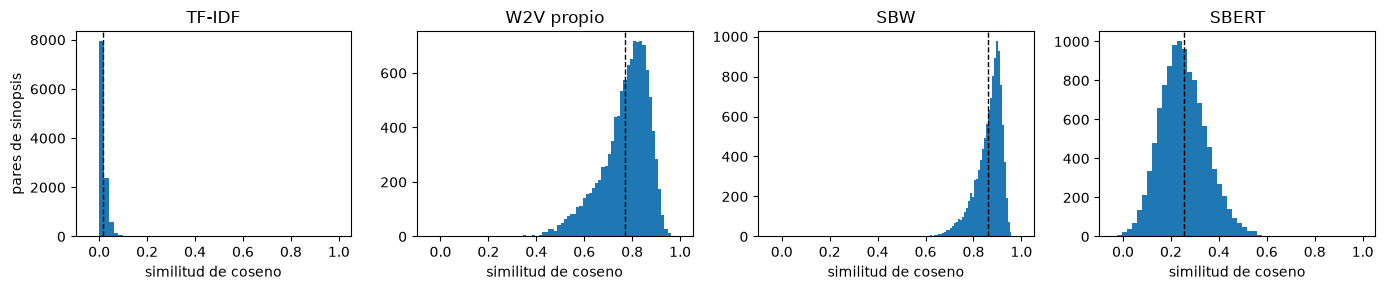

In [96]:
# Índices de todos los pares (i, j) con i < j
pares_i, pares_j = np.triu_indices(len(df_sinopsis), k=1)

# Similitud de cada par en cada modelo
sims_pares = {"TF-IDF": (M_tfidf @ M_tfidf.T).toarray()[pares_i, pares_j]}
for nombre, M in MATRICES.items():
    sims_pares[nombre] = (M @ M.T)[pares_i, pares_j]

resumen = pd.DataFrame({
    m: {"media": s.mean(), "desvío": s.std(), "mínimo": s.min(), "percentil 5": np.percentile(s, 5),
        "percentil 95": np.percentile(s, 95), "máximo": s.max()}
    for m, s in sims_pares.items()
}).T[["media", "desvío", "mínimo", "percentil 5", "percentil 95", "máximo"]].round(3)
display(resumen)

# Un histograma por modelo, todos con el mismo eje horizontal para poder compararlos
fig, ejes = plt.subplots(1, 4, figsize=(14, 3), sharex=True)
for eje, m in zip(ejes, MODELOS):
    eje.hist(sims_pares[m], bins=50)
    eje.axvline(sims_pares[m].mean(), color="black", linestyle="--", linewidth=1)
    eje.set_title(m)
    eje.set_xlabel("similitud de coseno")
ejes[0].set_ylabel("pares de sinopsis")
plt.tight_layout()
plt.show()

In [97]:
# El ejemplo de la Parte C, puesto en la escala de cada modelo: ¿qué porcentaje de los pares de sinopsis
# tiene una similitud menor que la de "una novela sobre piratas" / "un relato de bucaneros"?
for m, valor in [("SBW", float(wa @ wb)), ("SBERT", float(va @ vb))]:
    print(f"{m:6} similitud {valor:.3f} -> supera al {np.mean(sims_pares[m] < valor):.1%} de los pares de sinopsis")

SBW    similitud 0.777 -> supera al 8.4% de los pares de sinopsis
SBERT  similitud 0.513 -> supera al 99.2% de los pares de sinopsis


#### Lectura de las distribuciones

- **TF-IDF** (media 0,015): la gran mayoría de los pares casi no comparte términos. Distingue mucho, pero solo por coincidencia de palabras.
- **SBW** (media 0,862, desvío 0,055): el 90 % de los pares está entre 0,75 y 0,93. Para este modelo todas las sinopsis se parecen, y el ranking se decide por diferencias de centésimas. El **Word2Vec propio** tiene el mismo problema, algo menos marcado (media 0,770, desvío 0,099).
- **SBERT** (media 0,253, desvío 0,096): los valores van de −0,05 a alrededor de 0,6. Es el espacio de embeddings donde un par muy parecido se despega más del resto.

El máximo de 1,0 en todos los modelos corresponde a un par de libros con la misma sinopsis: "Los muchos mundos de Poul Anderson" I y II.

Esto responde lo que quedó pendiente en la Parte C. La similitud de 0,777 que SBW da a "una novela sobre piratas" / "un relato de bucaneros" parecía alta, pero está por debajo del 91,6 % de los pares de sinopsis: en la escala de SBW es un valor bajo. El 0,513 de SBERT, en cambio, supera al 99,2 % de los pares. Salvedad: se comparan dos frases de cuatro palabras contra una distribución hecha con sinopsis largas, y en los modelos de promedio un texto largo probablemente quede más cerca del "centro" del espacio que uno corto, así que la comparación es orientativa.

### Proyección 2D coloreada por género

Los géneros son multi-etiqueta y "Ciencia ficción" está en todos los libros, así que para colorear hace falta **una** etiqueta por libro. Se arma con esta prioridad: primero un género temático con al menos 5 libros (Fantástico, Aventuras, Juvenil), después el formato Relato, y si el libro no tiene nada de eso queda como "Solo ciencia ficción". Es una simplificación: un libro que es Fantástico y Juvenil a la vez se pinta solo como Fantástico.

Se usa PCA, que conserva las direcciones de mayor varianza y permite informar cuánta varianza retienen las dos componentes.

In [98]:
def etiqueta_color(generos):
    # Una sola etiqueta por libro, por orden de prioridad (ver el texto de arriba)
    if "Fantástico" in generos:
        return "Fantástico"
    if "Aventuras" in generos:
        return "Aventuras"
    if any(g in generos for g in ["Juvenil", "Infantil y juvenil", "Infantil"]):
        return "Juvenil"
    if "Relato" in generos:
        return "Relato"
    return "Solo ciencia ficción"

df_sinopsis["etiqueta"] = df_sinopsis["generos"].apply(etiqueta_color)
print(df_sinopsis["etiqueta"].value_counts().to_string())

etiqueta
Solo ciencia ficción    102
Fantástico               21
Relato                   17
Aventuras                 5
Juvenil                   5


W2V propio  varianza explicada por 2 componentes: 32.6%  (25.2% + 7.4%)
SBW         varianza explicada por 2 componentes: 23.9%  (16.9% + 7.0%)
SBERT       varianza explicada por 2 componentes: 10.2%  (6.0% + 4.3%)


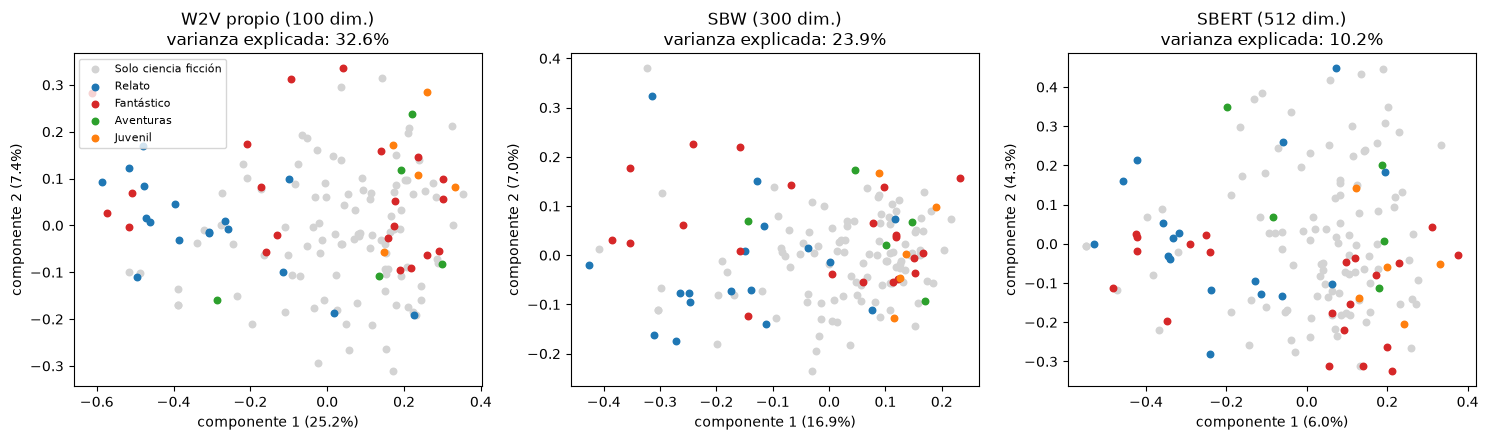

In [99]:
ORDEN_ETIQUETAS = ["Solo ciencia ficción", "Relato", "Fantástico", "Aventuras", "Juvenil"]
COLORES = dict(zip(ORDEN_ETIQUETAS, ["lightgray", "tab:blue", "tab:red", "tab:green", "tab:orange"]))

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
for eje, (nombre, M) in zip(ejes, MATRICES.items()):
    # PCA a 2 componentes y varianza que explica cada una
    pca = PCA(n_components=2, random_state=SEMILLA)
    puntos = pca.fit_transform(M)
    var1, var2 = pca.explained_variance_ratio_
    for etiqueta in ORDEN_ETIQUETAS:
        mascara = (df_sinopsis["etiqueta"] == etiqueta).to_numpy()
        eje.scatter(puntos[mascara, 0], puntos[mascara, 1], s=22, color=COLORES[etiqueta], label=etiqueta)
    eje.set_title(f"{nombre} ({M.shape[1]} dim.)\nvarianza explicada: {var1 + var2:.1%}")
    eje.set_xlabel(f"componente 1 ({var1:.1%})")
    eje.set_ylabel(f"componente 2 ({var2:.1%})")
    print(f"{nombre:11} varianza explicada por 2 componentes: {var1 + var2:.1%}  ({var1:.1%} + {var2:.1%})")
ejes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Como la proyección descarta la mayor parte de la varianza, se mide también en el **espacio original**, sin proyectar: la similitud media entre libros de la misma etiqueta contra la de libros de etiquetas distintas. Si el espacio agrupara por género, la primera sería claramente mayor.

In [100]:
# Para cada par de sinopsis: ¿tienen la misma etiqueta?
etiquetas = df_sinopsis["etiqueta"].to_numpy()
misma = etiquetas[pares_i] == etiquetas[pares_j]

# Se excluye "Solo ciencia ficción": no es un género, es la ausencia de etiqueta temática
con_tema = (etiquetas[pares_i] != "Solo ciencia ficción") & (etiquetas[pares_j] != "Solo ciencia ficción")

separacion = pd.DataFrame({
    m: {"misma etiqueta": s[con_tema & misma].mean(),
        "distinta etiqueta": s[con_tema & ~misma].mean(),
        "diferencia": s[con_tema & misma].mean() - s[con_tema & ~misma].mean(),
        "diferencia / desvío": (s[con_tema & misma].mean() - s[con_tema & ~misma].mean()) / s.std()}
    for m, s in sims_pares.items()
}).T.round(3)
print(f"Pares con la misma etiqueta: {int((con_tema & misma).sum())} | con distinta etiqueta: {int((con_tema & ~misma).sum())}")
display(separacion)

Pares con la misma etiqueta: 366 | con distinta etiqueta: 762


,misma etiqueta,distinta etiqueta,diferencia,diferencia / desvío
TF-IDF,0.022,0.015,0.007,0.355
W2V propio,0.754,0.720,0.034,0.337
SBW,0.860,0.853,0.007,0.135
SBERT,0.261,0.242,0.019,0.195


#### Lectura de la proyección

- **Advertencia.** Las dos componentes explican el 32,6 % de la varianza en el Word2Vec propio, el 23,9 % en SBW y el 10,2 % en SBERT. El gráfico de SBERT descarta casi el 90 % de la información: dos puntos que se ven juntos pueden estar lejos en el espacio original, y una nube que se ve mezclada podría estar separada en las dimensiones que no se muestran.
- **Qué se ve.** Las etiquetas aparecen mezcladas en los tres modelos. La única tendencia es que los libros de "Relato" quedan hacia la izquierda de la primera componente. Al mirar qué libros caen en cada extremo, de un lado están las antologías y recopilaciones, cuyas sinopsis describen el libro y a sus autores, y del otro las sinopsis que cuentan una trama. La primera componente separa el **tipo de texto**, no el género.
- **En el espacio original.** La similitud media entre libros de la misma etiqueta es apenas mayor que entre libros de etiquetas distintas: la diferencia va de 0,007 a 0,034 según el modelo, entre 0,14 y 0,36 desvíos. Ningún modelo agrupa los libros según esta etiqueta, y el resultado no depende de la proyección.
- **Límite de la etiqueta.** Esto no prueba que los modelos sean malos: la etiqueta es débil. El 68 % de los libros no tiene género temático, "Relato" es un formato, y se fuerza una sola etiqueta en un problema multi-etiqueta.

## Parte E - Persistencia e indexado

In [101]:
from dotenv import load_dotenv

# La cadena de conexión nunca se escribe en el notebook: se lee de afuera.
#   - En Colab: panel "Secrets" (ícono de llave), secreto DATABASE_URL con acceso habilitado para este notebook.
#   - En local: archivo .env en la raíz del repo (está en .gitignore; ver .env.example y el README).
DATABASE_URL = None
if EN_COLAB:
    from google.colab import userdata
    try:
        DATABASE_URL = userdata.get("DATABASE_URL")
    except Exception:
        pass   # el secreto no existe o no tiene acceso habilitado
else:
    load_dotenv(RAIZ / ".env.example")
    DATABASE_URL = os.environ.get("DATABASE_URL")

# Nunca se imprime la URL (contiene la contraseña): solo si se encontró o no
if DATABASE_URL:
    print("Credencial de Supabase cargada.")
else:
    print("No se encontró DATABASE_URL: las celdas que usan la base se omiten.")

Credencial de Supabase cargada.


In [102]:
# Esquema: una tabla por modelo, cada una con la dimensión de sus vectores.
# generos es un array de texto (text[]) para poder filtrar por género en SQL: WHERE 'Terror' = ANY(generos)
# Se borran y se vuelven a crear para que el notebook dé el mismo resultado cada vez que se ejecuta.
SQL_ESQUEMA = '''
CREATE EXTENSION IF NOT EXISTS vector;

DROP TABLE IF EXISTS libros_word2vec;
CREATE TABLE libros_word2vec (
    id        text PRIMARY KEY,
    titulo    text NOT NULL,
    generos   text[] NOT NULL,
    embedding vector(300) NOT NULL    -- promedio de vectores de palabra de SBW
);

DROP TABLE IF EXISTS libros_sbert;
CREATE TABLE libros_sbert (
    id        text PRIMARY KEY,
    titulo    text NOT NULL,
    generos   text[] NOT NULL,
    embedding vector(512) NOT NULL    -- distiluse-base-multilingual-cased-v1
);
'''

# BASE_DISPONIBLE indica a las celdas siguientes si se pudo trabajar con la base
BASE_DISPONIBLE = False
if DATABASE_URL:
    try:
        conn = psycopg2.connect(DATABASE_URL)
    except psycopg2.OperationalError as error:
        # No se imprime la URL. El mensaje del servidor nombra el host, pero nunca la contraseña.
        print("No se pudo conectar a Supabase:", str(error).strip().splitlines()[0])
        print("Si el error es de nombre de host o de red: usar la cadena 'Session pooler' del panel de Supabase"
              " (la conexión directa solo funciona con IPv6) y verificar que el proyecto no esté pausado.")
    else:
        # "with conn" confirma los cambios si todo salió bien y los deshace si hubo un error
        try:
            with conn, conn.cursor() as cur:
                cur.execute(SQL_ESQUEMA)
            BASE_DISPONIBLE = True
            print("Tablas 'libros_word2vec' y 'libros_sbert' creadas.")
        finally:
            conn.close()
else:
    print("Sin credencial: no se crean las tablas.")

Tablas 'libros_word2vec' y 'libros_sbert' creadas.


### Por qué una tabla por modelo

En pgvector la dimensión es parte del tipo de la columna (`vector(300)` y `vector(512)` son tipos distintos) y un índice solo se puede construir sobre una columna de dimensión fija. Por eso los vectores de SBW y los de SBERT no pueden compartir una columna indexada, y cada modelo va en su propia tabla.

### Carga de los vectores

Antes de insertar se descarta explícitamente todo vector que no sirva: nulo, de dimensión distinta a la de la tabla, con algún valor no finito (`NaN` o infinito) o de norma cero. La celda informa cuántos se descartaron en cada tabla.

In [103]:
from psycopg2.extras import execute_values

def vector_valido(v, dimension):
    # Solo se inserta un vector que existe, tiene la dimensión de la tabla, es finito en todos sus valores y no es el vector cero
    return (v is not None and len(v) == dimension
            and bool(np.isfinite(v).all()) and float(np.linalg.norm(v)) > 0)

def a_texto_pgvector(v):
    # pgvector recibe el vector como texto con el formato '[0.1,0.2,...]'
    return "[" + ",".join(f"{x:.9g}" for x in v) + "]"

def cargar_tabla(cur, tabla, columna_vector, dimension):
    # 1) Control previo: se separan los vectores válidos de los que no se pueden insertar
    validos = df_sinopsis[columna_vector].apply(lambda v: vector_valido(v, dimension))
    # 2) Una fila por libro: id, título, géneros (lista de Python -> text[]) y el vector como texto
    filas = [(f.id, f.titulo, f.generos, a_texto_pgvector(getattr(f, columna_vector)))
             for f in df_sinopsis[validos].itertuples()]
    # 3) Inserción en bloque; si el id ya existe se actualiza, así la celda se puede volver a ejecutar
    execute_values(cur, f'''
        INSERT INTO {tabla} (id, titulo, generos, embedding) VALUES %s
        ON CONFLICT (id) DO UPDATE
        SET titulo = EXCLUDED.titulo, generos = EXCLUDED.generos, embedding = EXCLUDED.embedding
    ''', filas, template="(%s, %s, %s, %s::vector)")
    print(f"{tabla}: {len(filas)} vectores insertados, {int((~validos).sum())} descartados por no ser válidos")

if BASE_DISPONIBLE:
    conn = psycopg2.connect(DATABASE_URL)
    try:
        with conn, conn.cursor() as cur:
            cargar_tabla(cur, "libros_word2vec", "vec_sbw", 300)
            cargar_tabla(cur, "libros_sbert", "vec_sbert", 512)
    finally:
        conn.close()
else:
    print("Base no disponible: no se cargan los vectores.")

libros_word2vec: 150 vectores insertados, 0 descartados por no ser válidos
libros_sbert: 150 vectores insertados, 0 descartados por no ser válidos


### Índice HNSW

La búsqueda de la Parte F ordena por **distancia de coseno**, que en pgvector es el operador `<=>`. Un índice solo sirve para el operador con el que fue creado, y eso se indica con la *opclass*: para `<=>` corresponde `vector_cosine_ops` (para la distancia euclídea `<->` sería `vector_l2_ops`, y para el producto interno `<#>`, `vector_ip_ops`). Si la opclass no coincide con el operador de la consulta, Postgres no usa el índice.

Se eligió coseno porque es la medida usada en todo el notebook y los vectores están normalizados.

In [104]:
# Un índice HNSW por tabla, con la opclass del operador de coseno (<=>)
SQL_INDICES = '''
CREATE INDEX IF NOT EXISTS libros_word2vec_embedding_hnsw
    ON libros_word2vec USING hnsw (embedding vector_cosine_ops);
CREATE INDEX IF NOT EXISTS libros_sbert_embedding_hnsw
    ON libros_sbert USING hnsw (embedding vector_cosine_ops);
'''

if BASE_DISPONIBLE:
    conn = psycopg2.connect(DATABASE_URL)
    try:
        with conn, conn.cursor() as cur:
            cur.execute(SQL_INDICES)
        print("Índices HNSW creados.")
    finally:
        conn.close()
else:
    print("Base no disponible: no se crean los índices.")

Índices HNSW creados.


### Verificación de lo que quedó en la base

Se consulta la base para comprobar la cantidad de filas, que los vectores guardados sigan teniendo norma 1 y con qué opclass quedó cada índice.

In [105]:
if BASE_DISPONIBLE:
    conn = psycopg2.connect(DATABASE_URL)
    try:
        with conn.cursor() as cur:
            for tabla in ["libros_word2vec", "libros_sbert"]:
                # Cantidad de filas, dimensión y rango de normas de los vectores guardados
                cur.execute(f"SELECT count(*), min(vector_dims(embedding)), min(vector_norm(embedding)), max(vector_norm(embedding)) FROM {tabla}")
                filas, dimension, norma_min, norma_max = cur.fetchone()
                print(f"{tabla}: {filas} filas | dimensión {dimension} | normas entre {norma_min:.4f} y {norma_max:.4f}")
            # Definición de los índices tal como la guarda Postgres (incluye la opclass)
            cur.execute("SELECT indexdef FROM pg_indexes WHERE indexname LIKE '%_embedding_hnsw' ORDER BY indexname")
            for (definicion,) in cur.fetchall():
                print(definicion)
    finally:
        conn.close()
else:
    print("Base no disponible: no se verifica.")

libros_word2vec: 150 filas | dimensión 300 | normas entre 1.0000 y 1.0000
libros_sbert: 150 filas | dimensión 512 | normas entre 1.0000 y 1.0000
CREATE INDEX libros_sbert_chunks_embedding_hnsw ON public.libros_sbert_chunks USING hnsw (embedding vector_cosine_ops)
CREATE INDEX libros_sbert_embedding_hnsw ON public.libros_sbert USING hnsw (embedding vector_cosine_ops)
CREATE INDEX libros_word2vec_embedding_hnsw ON public.libros_word2vec USING hnsw (embedding vector_cosine_ops)


## Parte F - Búsqueda semántica

`buscar(consulta, k)` convierte la consulta en un vector con el mismo modelo que se usó para los documentos y deja que **Postgres** calcule la similitud, ordene y recorte: Python no compara vectores. El filtro por género va en la misma consulta SQL, sobre la columna `generos`.

In [106]:
# Tabla de cada modelo y función que convierte la consulta en un vector de ese modelo
TABLAS = {
    "sbert": ("libros_sbert", lambda texto: sbert.encode(texto, normalize_embeddings=True)),
    "sbw":   ("libros_word2vec", lambda texto: vector_documento(texto, sbw)[0]),
}

def buscar(consulta, k=5, modelo="sbert", genero=None):
    # Devuelve los k libros más parecidos a la consulta. Con genero, solo entre los libros de ese género.
    if not BASE_DISPONIBLE:
        print("Base no disponible: no se puede buscar.")
        return None
    tabla, vectorizar = TABLAS[modelo]
    vector = vectorizar(consulta)
    if vector is None:     # solo puede pasar con SBW: ninguna palabra de la consulta tiene vector
        print("La consulta no tiene ninguna palabra con vector en este modelo.")
        return None

    # <=> es la distancia de coseno de pgvector (el operador para el que se creó el índice); similitud = 1 - distancia.
    # El nombre de la tabla sale del diccionario TABLAS, nunca de lo que escribe el usuario.
    sql = f'''
        SELECT id, titulo, generos, 1 - (embedding <=> %(v)s::vector) AS similitud
        FROM {tabla}
        WHERE %(genero)s::text IS NULL OR %(genero)s::text = ANY(generos)
        ORDER BY embedding <=> %(v)s::vector
        LIMIT %(k)s
    '''
    conn = psycopg2.connect(DATABASE_URL)
    try:
        with conn.cursor() as cur:
            cur.execute(sql, {"v": a_texto_pgvector(vector), "genero": genero, "k": k})
            filas = cur.fetchall()
    finally:
        conn.close()
    return pd.DataFrame(filas, columns=["id", "titulo", "generos", "similitud"]).round({"similitud": 3})

In [107]:
# Búsqueda sin filtro, con los dos modelos guardados en la base
consulta = "una nave espacial perdida o accidentada lejos de casa"
for modelo in ["sbert", "sbw"]:
    print(f"\n«{consulta}» | modelo: {modelo}")
    display(buscar(consulta, k=5, modelo=modelo))


«una nave espacial perdida o accidentada lejos de casa» | modelo: sbert


,id,titulo,generos,similitud
0,34537,Cuando chocan los mundos,"[Ciencia ficción, Novela]",0.444
1,12720,Los guardianes de la paz,"[Ciencia ficción, Novela]",0.425
2,54256,Un destello en el cielo,"[Ciencia ficción, Novela]",0.368
3,29001,Extraños en la luna,"[Aventuras, Ciencia ficción, Novela]",0.346
4,111401,Orfanato,"[Ciencia ficción, Novela]",0.345



«una nave espacial perdida o accidentada lejos de casa» | modelo: sbw


,id,titulo,generos,similitud
0,111401,Orfanato,"[Ciencia ficción, Novela]",0.815
1,12720,Los guardianes de la paz,"[Ciencia ficción, Novela]",0.810
2,110518,Horizonte de estrellas,"[Ciencia ficción, Novela]",0.804
3,36397,Los duplicadores,"[Ciencia ficción, Relato]",0.783
4,19608,Tógar,"[Ciencia ficción, Novela]",0.770


In [108]:
# La misma idea combinada con un filtro por metadata: solo libros que tengan el género indicado
consulta = "criaturas monstruosas que acechan a los protagonistas"
for genero in [None, "Terror", "Juvenil"]:
    print(f"\n«{consulta}» | género: {genero or 'sin filtro'}")
    display(buscar(consulta, k=3, genero=genero))


«criaturas monstruosas que acechan a los protagonistas» | género: sin filtro


,id,titulo,generos,similitud
0,120428,Ahí fuera gritando,"[Ciencia ficción, Fantástico, Relato, Terror]",0.336
1,107404,Los herederos de Hammerfell,"[Ciencia ficción, Fantástico, Novela, Otros]",0.314
2,14143,La isla del dragón,"[Ciencia ficción, Novela]",0.298



«criaturas monstruosas que acechan a los protagonistas» | género: Terror


,id,titulo,generos,similitud
0,120428,Ahí fuera gritando,"[Ciencia ficción, Fantástico, Relato, Terror]",0.336
1,2386,La marcha zombi,"[Ciencia ficción, Relato, Terror]",0.263
2,1596,La ensenada Calibán,"[Ciencia ficción, Terror]",0.176



«criaturas monstruosas que acechan a los protagonistas» | género: Juvenil


,id,titulo,generos,similitud
0,12890,La reacción,"[Ciencia ficción, Infantil, Juvenil, Novela]",0.186
1,11823,Preciada,"[Ciencia ficción, Fantástico, Juvenil, Novela]",0.151
2,45330,Atados a las estrellas,"[Ciencia ficción, Juvenil, Novela, Romántico]",0.124


*Control:* los 5 primeros que devuelve SQL tienen que ser los mismos que se calculan en memoria con NumPy (Parte D), porque los dos usan los mismos vectores y la misma medida. Se comparan como conjuntos: el corpus tiene dos libros con la misma sinopsis ("Los muchos mundos de Poul Anderson" I y II), que empatan en similitud, y el orden entre ellos es arbitrario.

In [109]:
if BASE_DISPONIBLE:
    for modelo, nombre_matriz in [("sbert", "SBERT"), ("sbw", "SBW")]:
        coinciden = 0
        for q in queries.values():
            # Los 5 primeros según Postgres y según NumPy, para cada consulta del conjunto de evaluación
            ids_sql = set(buscar(q["consulta"], k=5, modelo=modelo)["id"])
            sims = similitudes(q["consulta"], nombre_matriz)
            ids_numpy = set(df_sinopsis["id"].iloc[np.argsort(sims)[::-1][:5]])
            coinciden += ids_sql == ids_numpy
        print(f"{modelo}: los 5 primeros de SQL coinciden con los de NumPy en {coinciden} de {len(queries)} consultas")

sbert: los 5 primeros de SQL coinciden con los de NumPy en 18 de 18 consultas
sbw: los 5 primeros de SQL coinciden con los de NumPy en 18 de 18 consultas


### El problema de recall al combinar un índice aproximado con un filtro selectivo

HNSW no revisa toda la tabla: recorre el índice y se queda con una cantidad limitada de candidatos cercanos (`hnsw.ef_search`). El filtro `WHERE` se aplica **después**, sobre esos candidatos. Si el filtro es muy selectivo, la mayoría de los candidatos se descarta y la consulta puede devolver menos de *k* resultados, aunque en la tabla existan libros que cumplen el filtro.

Con 150 filas Postgres no usa el índice (le resulta más barato recorrer la tabla, y ese recorrido es exacto), así que para ver el problema se lo obliga a usarlo. Se busca dentro del género "Terror", que tiene solo 4 libros, pidiendo *k* = 4.

In [110]:
def buscar_con_configuracion(consulta, k, genero, ajustes):
    # Igual que buscar() sobre libros_sbert, pero aplicando ajustes de Postgres solo dentro de esta transacción (SET LOCAL)
    vector = a_texto_pgvector(sbert.encode(consulta, normalize_embeddings=True))
    sql = '''
        SELECT titulo FROM libros_sbert
        WHERE %(genero)s = ANY(generos)
        ORDER BY embedding <=> %(v)s::vector
        LIMIT %(k)s
    '''
    parametros = {"v": vector, "genero": genero, "k": k}
    conn = psycopg2.connect(DATABASE_URL)
    try:
        with conn, conn.cursor() as cur:
            for ajuste in ajustes:
                cur.execute(f"SET LOCAL {ajuste}")
            # EXPLAIN muestra el plan elegido: interesa si recorre la tabla (Seq Scan) o usa el índice (Index Scan)
            cur.execute("EXPLAIN " + sql, parametros)
            plan = " ".join(fila[0] for fila in cur.fetchall())
            usa_indice = "libros_sbert_embedding_hnsw" in plan
            cur.execute(sql, parametros)
            titulos = [fila[0] for fila in cur.fetchall()]
    finally:
        conn.close()
    return usa_indice, titulos

if BASE_DISPONIBLE:
    consulta, genero, k = "criaturas monstruosas que acechan a los protagonistas", "Terror", 4
    configuraciones = {
        "Por defecto (Postgres elige el plan)": [],
        "Índice HNSW forzado, ef_search = 10": ["enable_seqscan = off", "hnsw.ef_search = 10"],
        "Índice HNSW forzado, ef_search = 150": ["enable_seqscan = off", "hnsw.ef_search = 150"],
        "Índice HNSW forzado, ef_search = 10, escaneo iterativo": ["enable_seqscan = off", "hnsw.ef_search = 10",
                                                                   "hnsw.iterative_scan = strict_order"],
    }
    filas = []
    for nombre, ajustes in configuraciones.items():
        usa_indice, titulos = buscar_con_configuracion(consulta, k, genero, ajustes)
        filas.append({"configuración": nombre, "usa el índice": "sí" if usa_indice else "no",
                      "resultados": f"{len(titulos)} de {k}", "títulos": " | ".join(t[:22] for t in titulos)})
    display(pd.DataFrame(filas))

,configuración,usa el índice,resultados,títulos
0,Por defecto (Postgres elige el plan),no,4 de 4,Ahí fuera gritando | La marcha zombi | La ensenada Calibán | El vigilante
1,"Índice HNSW forzado, ef_search = 10",sí,2 de 4,Ahí fuera gritando | La marcha zombi
2,"Índice HNSW forzado, ef_search = 150",sí,4 de 4,Ahí fuera gritando | La marcha zombi | La ensenada Calibán | El vigilante
3,"Índice HNSW forzado, ef_search = 10, escaneo iterativo",sí,4 de 4,Ahí fuera gritando | La marcha zombi | La ensenada Calibán | El vigilante


#### Resultado

- **Por defecto**, Postgres no usa el índice: recorre las 150 filas, aplica el filtro y ordena. El resultado es exacto: devuelve los 4 libros de Terror.
- **Con el índice forzado y `ef_search = 10`** devuelve solo 2 de 4. El índice entregó sus 10 candidatos más cercanos a la consulta, solo 2 eran de Terror, y los otros 2 libros del género quedaron afuera aunque existen en la tabla. El recall cayó al 50 % sin ningún error ni aviso.
- **Con `ef_search = 150`** (tantos candidatos como filas) vuelve a devolver los 4, pero a costa de revisar todo.
- **Con el escaneo iterativo** de pgvector (`hnsw.iterative_scan`, disponible desde la versión 0.8), el índice sigue buscando candidatos hasta juntar *k* resultados que cumplan el filtro, y devuelve los 4 con `ef_search = 10`.

**Qué haríamos al respecto.** En este corpus, nada: con 150 filas la búsqueda exacta es instantánea y Postgres ya la elige solo, así que `buscar` no pierde resultados. En un catálogo grande, donde el índice sí se usa, las opciones son activar el escaneo iterativo, subir `ef_search` cuando hay filtro, o crear un índice parcial por género (`CREATE INDEX ... WHERE 'Terror' = ANY(generos)`) si se filtra seguido por pocos valores.

## Parte 5 - Evaluación de los modelos

Se calcula precision@3 y precision@5 sobre las 18 consultas de `queries.json` para TF-IDF, los tres modelos de embeddings y una selección al azar. Se usa el mismo criterio que en la Parte D: solo cuentan como devueltos los libros con similitud mayor que cero. Se usa k = 3 y k = 5 porque varias consultas tienen menos de 5 relevantes.

In [111]:
# Ids en el mismo orden que las filas de las matrices de la Parte D
IDS = df_sinopsis["id"].to_numpy()
N = len(IDS)
limpio_por_id = dict(zip(df_sinopsis["id"], df_sinopsis["sinopsis_limpio"]))
titulo_por_id = dict(zip(df_sinopsis["id"], df_sinopsis["titulo"]))

def tipo_de(q):
    # queries.json marca con sin_palabras_en_comun las consultas diseñadas para no compartir palabras con sus relevantes
    return "sin palabras en común" if q.get("sin_palabras_en_comun") else "comparte palabras"

def relevantes_de(q):
    return {r["id"] for r in q["relevantes"]}

# Por consulta: cantidad de relevantes, ids que no existen en el corpus y palabras que comparte con sus relevantes
filas = []
for qid, q in queries.items():
    rel = relevantes_de(q)
    tokens_q = set(limpiar_texto(q["consulta"]).split())
    compartidas = set().union(*(tokens_q & set(limpio_por_id[i].split()) for i in rel if i in limpio_por_id))
    filas.append({"id": qid, "tipo": tipo_de(q), "consulta": q["consulta"], "relevantes": len(rel),
                  "ids inexistentes": len(rel - set(IDS)),
                  "palabras compartidas con los relevantes": ", ".join(sorted(compartidas)) or "ninguna"})
revision = pd.DataFrame(filas)
display(revision)
print(f"Consultas: {len(revision)} | relevantes por consulta: entre {revision['relevantes'].min()} y {revision['relevantes'].max()}")

,id,tipo,consulta,relevantes,ids inexistentes,palabras compartidas con los relevantes
0,q01,comparte palabras,viajes en el tiempo para cambiar el pasado,6,0,"pasado, tiempo"
1,q02,comparte palabras,una enfermedad o plaga que extermina a casi toda la humanidad,5,0,"enfermedad, humanidad, plaga"
2,q03,comparte palabras,la Tierra queda devastada por una guerra y los supervivientes intentan seguir adelante,4,0,"devastada, guerra, queda, supervivientes, tierra"
3,q04,comparte palabras,extraterrestres hostiles que atacan o quieren dominar la Tierra,5,0,"extraterrestres, tierra"
4,q05,comparte palabras,primer contacto con una inteligencia no humana y la dificultad de entenderse con ella,5,0,"contacto, humana, inteligencia"
5,q06,comparte palabras,robots e inteligencias artificiales,5,0,robots
6,q07,comparte palabras,sociedades totalitarias donde el gobierno vigila y controla a la población,9,0,"controla, gobierno, vigila"
7,q08,comparte palabras,telepatía y personas con poderes mentales,6,0,"personas, telepatía"
8,q09,comparte palabras,universos paralelos,4,0,"paralelos, universos"
9,q10,comparte palabras,guerras espaciales entre imperios y ejércitos,8,0,guerras


Consultas: 18 | relevantes por consulta: entre 2 y 11


In [112]:
def top_k_ids(consulta, modelo, k):
    # Los k libros más similares, con el mismo criterio que ranking(): solo similitud mayor que cero
    sims = similitudes(consulta, modelo)
    if sims is None:
        return []
    return [IDS[i] for i in np.argsort(sims)[::-1][:k] if sims[i] > 0]

def evaluar(k):
    filas = []
    for qid, q in queries.items():
        rel = relevantes_de(q)
        fila = {"id": qid, "tipo": tipo_de(q), "relevantes": len(rel)}
        for m in MODELOS:
            fila[m] = len(rel & set(top_k_ids(q["consulta"], m, k))) / k
        fila["Azar (piso)"] = len(rel) / N               # valor esperado al elegir k libros al azar
        fila["Máximo posible"] = min(len(rel), k) / k    # con menos de k relevantes, 1 es inalcanzable
        filas.append(fila)
    return pd.DataFrame(filas)

COLUMNAS = MODELOS + ["Azar (piso)", "Máximo posible"]
resultados = {k: evaluar(k) for k in [3, 5]}

for k, res in resultados.items():
    print(f"\nprecision@{k} por consulta")
    display(res.round(2))

print("\nPromedio sobre todas las consultas")
display(pd.DataFrame({f"precision@{k}": res[COLUMNAS].mean() for k, res in resultados.items()}).round(3))

print("Promedio por tipo de consulta (precision@5)")
display(resultados[5].groupby("tipo")[COLUMNAS].mean().round(3))

print("Consultas sin palabras en común con sus relevantes (TF-IDF no puede acertar por construcción)")
display(resultados[5][resultados[5]["tipo"] == "sin palabras en común"].round(2))


precision@3 por consulta


,id,tipo,relevantes,TF-IDF,W2V propio,SBW,SBERT,Azar (piso),Máximo posible
0,q01,comparte palabras,6,0.33,1.00,0.00,0.33,0.04,1.00
1,q02,comparte palabras,5,0.33,0.33,0.67,0.67,0.03,1.00
2,q03,comparte palabras,4,0.67,0.33,0.33,0.00,0.03,1.00
3,q04,comparte palabras,5,0.00,0.00,0.33,0.00,0.03,1.00
4,q05,comparte palabras,5,0.33,0.33,0.33,0.67,0.03,1.00
5,q06,comparte palabras,5,0.33,0.33,0.33,0.33,0.03,1.00
6,q07,comparte palabras,9,0.33,0.00,0.67,0.33,0.06,1.00
7,q08,comparte palabras,6,0.33,0.00,0.67,1.00,0.04,1.00
8,q09,comparte palabras,4,0.67,0.67,0.67,0.33,0.03,1.00
9,q10,comparte palabras,8,0.33,0.00,0.33,0.67,0.05,1.00



precision@5 por consulta


,id,tipo,relevantes,TF-IDF,W2V propio,SBW,SBERT,Azar (piso),Máximo posible
0,q01,comparte palabras,6,0.4,0.6,0.2,0.2,0.04,1.0
1,q02,comparte palabras,5,0.4,0.2,0.4,0.4,0.03,1.0
2,q03,comparte palabras,4,0.4,0.2,0.2,0.0,0.03,0.8
3,q04,comparte palabras,5,0.0,0.0,0.2,0.0,0.03,1.0
4,q05,comparte palabras,5,0.2,0.2,0.2,0.4,0.03,1.0
5,q06,comparte palabras,5,0.4,0.2,0.4,0.4,0.03,1.0
6,q07,comparte palabras,9,0.2,0.0,0.8,0.4,0.06,1.0
7,q08,comparte palabras,6,0.4,0.0,0.6,0.6,0.04,1.0
8,q09,comparte palabras,4,0.4,0.4,0.4,0.2,0.03,0.8
9,q10,comparte palabras,8,0.2,0.0,0.4,0.4,0.05,1.0



Promedio sobre todas las consultas


,precision@3,precision@5
TF-IDF,0.407,0.322
W2V propio,0.296,0.211
SBW,0.407,0.333
SBERT,0.407,0.300
Azar (piso),0.036,0.036
Máximo posible,0.981,0.900


Promedio por tipo de consulta (precision@5)


,TF-IDF,W2V propio,SBW,SBERT,Azar (piso),Máximo posible
tipo,,,,,,
comparte palabras,0.363,0.238,0.325,0.288,0.038,0.938
sin palabras en común,0.000,0.000,0.400,0.400,0.020,0.600


Consultas sin palabras en común con sus relevantes (TF-IDF no puede acertar por construcción)


,id,tipo,relevantes,TF-IDF,W2V propio,SBW,SBERT,Azar (piso),Máximo posible
16,q17,sin palabras en común,4,0.0,0.0,0.6,0.6,0.03,0.8
17,q18,sin palabras en común,2,0.0,0.0,0.2,0.2,0.01,0.4


In [113]:
rng_eval = np.random.default_rng(SEMILLA)

def azar_promedio(k, repeticiones=2000):
    # precision@k promedio sobre todas las consultas eligiendo k libros al azar, repetido muchas veces
    medias = [np.mean([len(relevantes_de(q) & set(rng_eval.choice(IDS, size=k, replace=False))) / k
                       for q in queries.values()])
              for _ in range(repeticiones)]
    return np.mean(medias), np.percentile(medias, 95)

for k, res in resultados.items():
    media, p95 = azar_promedio(k)
    print(f"\nprecision@{k} | azar: media {media:.3f}, percentil 95 {p95:.3f}")
    for m in MODELOS:
        valor = res[m].mean()
        print(f"  {m:11} {valor:.3f}  {'supera' if valor > p95 else 'NO supera'} al percentil 95 del azar")


precision@3 | azar: media 0.035, percentil 95 0.074
  TF-IDF      0.407  supera al percentil 95 del azar
  W2V propio  0.296  supera al percentil 95 del azar
  SBW         0.407  supera al percentil 95 del azar
  SBERT       0.407  supera al percentil 95 del azar

precision@5 | azar: media 0.036, percentil 95 0.067
  TF-IDF      0.322  supera al percentil 95 del azar
  W2V propio  0.211  supera al percentil 95 del azar
  SBW         0.333  supera al percentil 95 del azar
  SBERT       0.300  supera al percentil 95 del azar


In [114]:
res5 = resultados[5]

# Consulta por consulta: cuántas veces cada modelo gana, empata o pierde contra TF-IDF
for m in ["W2V propio", "SBW", "SBERT"]:
    print(f"{m:11} vs TF-IDF (p@5): gana {(res5[m] > res5['TF-IDF']).sum()}"
          f" | empata {(res5[m] == res5['TF-IDF']).sum()} | pierde {(res5[m] < res5['TF-IDF']).sum()}")

# Consultas donde ningún modelo encontró relevantes en el top 5: candidatas para el caso de falla del informe
sin_aciertos = res5[(res5[MODELOS] == 0).all(axis=1)]
print("\nConsultas sin ningún relevante en el top 5 de ningún modelo:", list(sin_aciertos["id"]) or "ninguna")

W2V propio  vs TF-IDF (p@5): gana 2 | empata 6 | pierde 10
SBW         vs TF-IDF (p@5): gana 6 | empata 6 | pierde 6
SBERT       vs TF-IDF (p@5): gana 6 | empata 5 | pierde 7

Consultas sin ningún relevante en el top 5 de ningún modelo: ninguna


In [115]:
def detalle(qid, k=5):
    q = queries[qid]
    rel = relevantes_de(q)
    print(f"{qid}: «{q['consulta']}»")
    print("Relevantes:", " | ".join(titulo_por_id[i] for i in rel if i in titulo_por_id))
    display(pd.DataFrame({m: ranking(q["consulta"], m, k=k, relevantes=rel) for m in MODELOS}, index=range(1, k + 1)))

detalle("q01")   # cambiar por la consulta a analizar

q01: «viajes en el tiempo para cambiar el pasado»
Relevantes: Solo contra el tiempo | Ruinas | La última Noche de Hipatia | Los pecios y los náufragos | Las encrucijadas del tiempo | Así se pierde la guerra del tiempo


,TF-IDF,W2V propio,SBW,SBERT
1,· La espada de Katham (0.15),✓ Así se pierde la guerra del tiem (0.88),· Viaje de un siglo (0.80),· Simulacron-3 (0.21)
2,✓ Solo contra el tiempo (0.15),✓ Las encrucijadas del tiempo (0.85),· Cómo sobrevivir al fin del mundo (0.79),✓ Las encrucijadas del tiempo (0.21)
3,· Salvation’s Reach (0.15),✓ Solo contra el tiempo (0.84),· El vigilante (0.79),· El día de la recuperación: los h (0.20)
4,✓ Así se pierde la guerra del tiem (0.13),· Viaje de un siglo (0.80),✓ Solo contra el tiempo (0.78),· El rival oscuro (0.19)
5,· Los muchos mundos de Poul Anders (0.12),· El alimento de los dioses (0.79),· Consigue un traje espacial: viaj (0.78),· Planetas Invisibles (0.17)


### Resultados de la evaluación

El conjunto tiene 18 consultas, con entre 2 y 11 relevantes cada una. Ninguna tiene ids inexistentes, y q17 y q18 no comparten ninguna palabra con sus relevantes.

| Modelo | precision@3 | precision@5 |
|---|---|---|
| Azar (piso) | 0,036 | 0,036 |
| TF-IDF | 0,407 | 0,322 |
| W2V propio | 0,296 | 0,211 |
| SBW | 0,407 | 0,333 |
| SBERT | 0,407 | 0,300 |
| Máximo posible | 0,981 | 0,900 |

**Contra el azar.** Los cuatro modelos superan con amplitud el percentil 95 de la selección al azar (0,074 en precision@3 y 0,067 en precision@5). Ninguno se parece a elegir libros al azar.

**Contra TF-IDF.** Ningún modelo de embeddings supera a TF-IDF en el promedio. En precision@3, TF-IDF, SBW y SBERT empatan en 0,407 (22 aciertos sobre 54 posiciones). En precision@5, SBW supera a TF-IDF por 0,011, que equivale a un solo acierto sobre 90 posiciones, y SBERT queda 0,022 por debajo (dos aciertos menos). Consulta por consulta, SBW gana 6, empata 6 y pierde 6; SBERT gana 6, empata 5 y pierde 7; el Word2Vec propio gana 2, empata 6 y pierde 10. Las diferencias entre TF-IDF, SBW y SBERT son demasiado chicas para ordenar los modelos con 18 consultas.

**Por tipo de consulta.** En las 16 consultas que comparten palabras con sus relevantes, TF-IDF tiene la mejor precision@5 (0,363), seguido por SBW (0,325), SBERT (0,288) y el Word2Vec propio (0,238). En q17 y q18, TF-IDF y el Word2Vec propio obtienen 0, mientras que SBW y SBERT llegan a 0,6 en q17 y a 0,2 en q18 (1 de los 2 relevantes). Es el único tipo de consulta donde los embeddings ganan de forma clara.

**Dónde gana cada uno.** TF-IDF gana con amplitud en q11 (antologías: 0,8 contra 0,2 de SBW y SBERT) y en q12 (Marte: 0,6 contra 0,2 y 0,4). En las dos, las palabras de la consulta aparecen literalmente en las sinopsis relevantes ("antologías", "relatos", "autores", "marte", "marcianos"). Los embeddings ganan en q07 (sociedades totalitarias: SBW 0,8 contra 0,2 de TF-IDF), q08 (telepatía: 0,6 contra 0,4) y q10 (guerras espaciales: 0,4 contra 0,2), donde TF-IDF comparte con los relevantes solo una o pocas palabras.

**Word2Vec propio.** Pierde contra TF-IDF en 10 de las 18 consultas. Su mejor resultado es q01 (precision@3 de 1,0): en el detalle, sus tres primeros libros son relevantes y los tres tienen "tiempo" en el título. En q17 y q18 no puede representar la consulta porque sus palabras no están en su vocabulario.

**Consulta más difícil.** q04 («extraterrestres hostiles que atacan o quieren dominar la Tierra») es la de peores resultados: TF-IDF, el Word2Vec propio y SBERT tienen precision@5 de 0, y SBW, 0,2. Todas las consultas tienen al menos un relevante en el top 5 de algún modelo.

In [116]:
posicion_libro = {i: n for n, i in enumerate(IDS)}

In [117]:
# Caso de falla: q04, la consulta con peores resultados de la evaluación
detalle("q04")

# Posición de cada libro relevante en el ranking de cada modelo, y palabras que comparte con la consulta
q = queries["q04"]
tokens_q = set(limpiar_texto(q["consulta"]).split())
filas = []
for i in relevantes_de(q):
    fila = {"libro": titulo_por_id[i],
            "palabras compartidas": ", ".join(sorted(tokens_q & set(limpio_por_id[i].split()))) or "ninguna",
            "tokens SBERT": int(df_sinopsis.loc[df_sinopsis["id"] == i, "n_tokens_sbert"].iloc[0])}
    for m in MODELOS:
        sims = similitudes(q["consulta"], m)
        fila[f"posición {m}"] = "-" if sims is None else int(np.where(np.argsort(sims)[::-1] == posicion_libro[i])[0][0]) + 1
    filas.append(fila)
display(pd.DataFrame(filas))

# Comienzo de la sinopsis de cada relevante
for i in relevantes_de(q):
    print(f"\n{titulo_por_id[i]}:\n  {df_sinopsis.loc[df_sinopsis['id'] == i, 'sinopsis_emb'].iloc[0][:400]}...")

q04: «extraterrestres hostiles que atacan o quieren dominar la Tierra»
Relevantes: Los últimos días de la Tierra | Barrera siniestra | Los visitantes | Orfanato | Trilogía de los Tres Cuerpos


,TF-IDF,W2V propio,SBW,SBERT
1,· Tiempo de cosecha (0.12),· Expedición a la Tierra (0.64),✓ Los últimos días de la Tierra (0.81),· Cuando chocan los mundos (0.42)
2,· La llegada (0.07),· Un par del espacio (0.56),· El efecto Lázaro (0.80),· Ecos de la Tierra (0.38)
3,· Estación Once (0.06),· La hija de Marte (0.56),· Milenio (0.79),· Tierra de titanes (0.36)
4,· Bajo la hiedra (0.06),· Cuando chocan los mundos (0.56),· La ensenada Calibán (0.79),· Expedición a la Tierra (0.34)
5,· Expedición a la Tierra (0.05),· Walkar bajo el terror (0.56),· Santa Sabbat mártir (0.79),· Solaris (trad. Matilde Horne) (0.34)


,libro,palabras compartidas,tokens SBERT,posición TF-IDF,posición W2V propio,posición SBW,posición SBERT
0,Los últimos días de la Tierra,tierra,309,9,8,1,8
1,Barrera siniestra,ninguna,158,136,53,50,31
2,Los visitantes,ninguna,155,119,90,30,56
3,Orfanato,tierra,186,21,10,12,16
4,Trilogía de los Tres Cuerpos,"extraterrestres, tierra",477,6,76,69,136



Los últimos días de la Tierra:
  Esta novela es, sin duda, una de las más interesantes de A. Thorkent, fuera del universo de su serie del Orden Estelar. Nos sitúa en un planeta Tierra devastado por una guerra nuclear e invadido por una raza extraterrestre («extres») que trata de aniquilar a los supervivientes humanos. La Humanidad, no muchos años antes, ya colonizaba la Luna, y su tecnología iba desarrollándose con normalidad, au...

Barrera siniestra:
  Al investigar las muertes, aparentemente accidentales, de unos científicos, el investigador Bill Graham descubre el hecho más terrible e insospechado de la historia de la humanidad, lo que le obliga a enfrentarse al más maligno y despiadado de los enemigos, en una lucha sin cuartel, en la que está en juego el propio destino del hombre. Recogiendo las teorías de Charles Fort y situada en nuestro fu...

Los visitantes:
  Todas las luces de la ciudad de Nueva York se cortan y se interrumpen las comunicaciones. Lo mismo ocurre en Moscú. ¿

### Caso de falla: q04

q04 («extraterrestres hostiles que atacan o quieren dominar la Tierra») es la consulta con peores resultados: TF-IDF, el Word2Vec propio y SBERT no ubican ningún relevante entre los 5 primeros, y SBW ubica uno.

| Libro relevante | Palabras compartidas | Tokens | TF-IDF | W2V propio | SBW | SBERT |
|---|---|---|---|---|---|---|
| Los últimos días de la Tierra | tierra | 309 | 9 | 8 | 1 | 8 |
| Orfanato | tierra | 186 | 21 | 10 | 12 | 16 |
| Trilogía de los Tres Cuerpos | extraterrestres, tierra | 477 | 6 | 76 | 69 | 136 |
| Barrera siniestra | ninguna | 158 | 136 | 53 | 50 | 31 |
| Los visitantes | ninguna | 155 | 119 | 90 | 30 | 56 |

(Posición de cada libro en el ranking de 150.)

**El único relevante bien ubicado es el que nombra a los extraterrestres al comienzo.** "Los últimos días de la Tierra" dice en su sinopsis que la Tierra fue "invadida por una raza extraterrestre" que intenta aniquilar a los supervivientes. Es el único que queda entre los 10 primeros en los cuatro modelos, y el primero en SBW.

**En tres de los relevantes, el comienzo de la sinopsis no dice que el enemigo sea extraterrestre.** "Barrera siniestra" habla de "el más maligno y despiadado de los enemigos" y de un descubrimiento "terrible e insospechado", sin decir cuál. "Los visitantes" describe un apagón en Nueva York y Moscú y plantea una pregunta ("¿Qué pasa?") sin responderla. "Orfanato" habla de proyectiles disparados desde Ganímedes, sin mencionar quién los dispara. Las sinopsis ocultan el giro de la trama para generar intriga, y ningún modelo puede recuperar lo que el texto no dice: "Barrera siniestra" y "Los visitantes" no comparten ninguna palabra con la consulta y quedan entre los puestos 30 y 136.

**"Trilogía de los Tres Cuerpos" falla por otra razón.** Su sinopsis tiene 477 tokens y empieza con texto promocional ("Edición completa", "premio Hugo", "obra maestra"). TF-IDF la ubica sexta porque la palabra "extraterrestres" aparece en algún lugar del texto, pero SBERT la deja en el puesto 136 de 150: el modelo solo ve los primeros 128 tokens, que son la parte promocional. El Word2Vec propio y SBW, que promedian todas las palabras, la ubican en los puestos 76 y 69.

**Qué devuelven los modelos en su lugar.** Los primeros resultados del Word2Vec propio y de SBERT son libros con "Tierra" o "mundos" en el título ("Expedición a la Tierra", "Ecos de la Tierra", "Tierra de titanes", "Cuando chocan los mundos"), que no están marcados como relevantes. Los modelos responden a "la Tierra" como tema, pero no a "extraterrestres hostiles" como agente de la trama, porque esa parte de la consulta no aparece explícita en la mayoría de las sinopsis relevantes.

**Hipótesis.** La falla no se debe a un solo modelo, sino al texto: las sinopsis son promocionales y ocultan quién es el enemigo, y en el caso más largo, la información relevante queda después del límite de SBERT. La relevancia de estos libros se decidió por algo que la sinopsis sugiere pero no dice.

## Parte 6 - Parte avanzada: Chunking

En la Parte C, 113 de las 150 sinopsis (75,3 %) superan el límite de 128 tokens de SBERT y se truncan. Se parten las sinopsis en fragmentos que entren en el límite, se guarda un vector por fragmento y se mide si mejora la búsqueda de los libros truncados.

In [118]:
def n_tok(texto):
    return len(sbert.tokenizer(texto, add_special_tokens=True)["input_ids"])

def partir_en_chunks(texto, max_tokens=limite):
    # Agrupa oraciones consecutivas mientras el fragmento no supere max_tokens
    oraciones = sent_tokenize(texto, language="spanish")
    chunks, actual = [], []
    for o in oraciones:
        if actual and n_tok(" ".join(actual + [o])) > max_tokens:
            chunks.append(" ".join(actual))
            actual = [o]
        else:
            actual.append(o)
    if actual:
        chunks.append(" ".join(actual))
    return chunks

df_chunks = pd.DataFrame([
    {"libro_id": f.id, "titulo": f.titulo, "generos": f.generos, "chunk_idx": j, "texto": ch}
    for f in df_sinopsis.itertuples()
    for j, ch in enumerate(partir_en_chunks(f.sinopsis_emb))
])
df_chunks["n_tokens"] = df_chunks["texto"].apply(n_tok)

por_libro = df_chunks.groupby("libro_id").size()
print(f"Chunks: {len(df_chunks)} para {N} libros | por libro: media {por_libro.mean():.1f}, máximo {por_libro.max()}")
print(f"Libros con un solo chunk (texto completo): {(por_libro == 1).sum()}")
print(f"Chunks que igual superan el límite (una sola oración muy larga): {(df_chunks['n_tokens'] > limite).sum()}")

Chunks: 322 para 150 libros | por libro: media 2.1, máximo 10
Libros con un solo chunk (texto completo): 37
Chunks que igual superan el límite (una sola oración muy larga): 5


In [119]:
emb_chunks = sbert.encode(
    df_chunks["texto"].tolist(), batch_size=16, show_progress_bar=False,
    normalize_embeddings=True, convert_to_numpy=True,
).astype(np.float32)

df_chunks["vec"] = list(emb_chunks)
print("Forma:", emb_chunks.shape)
print("Chunks con vector no válido:", int((~df_chunks["vec"].apply(lambda v: vector_valido(v, 512))).sum()))

np.save(DIR_DATA / "emb_sbert_chunks.npy", emb_chunks)
df_chunks.to_pickle(DIR_DATA / "chunks.pkl")

Forma: (322, 512)
Chunks con vector no válido: 0


In [121]:
import psycopg2

try:
    test_conn = psycopg2.connect(DATABASE_URL)
    test_conn.close()
    print("Conexión exitosa a la base de datos.")
except Exception as err:
    print(f"Detalle del fallo de conexión: {type(err).__name__} - {err}")

Conexión exitosa a la base de datos.


In [122]:
SQL_CHUNKS = '''
DROP TABLE IF EXISTS libros_sbert_chunks;
CREATE TABLE libros_sbert_chunks (
    libro_id  text NOT NULL,
    chunk_idx int  NOT NULL,
    titulo    text NOT NULL,
    generos   text[] NOT NULL,
    texto     text NOT NULL,
    embedding vector(512) NOT NULL,
    PRIMARY KEY (libro_id, chunk_idx)
);
'''

if BASE_DISPONIBLE:
    validos = df_chunks["vec"].apply(lambda v: vector_valido(v, 512))
    filas = [(f.libro_id, f.chunk_idx, f.titulo, f.generos, f.texto, a_texto_pgvector(f.vec))
             for f in df_chunks[validos].itertuples()]
    conn = psycopg2.connect(DATABASE_URL)
    try:
        with conn, conn.cursor() as cur:
            cur.execute(SQL_CHUNKS)
            execute_values(cur, '''
                INSERT INTO libros_sbert_chunks (libro_id, chunk_idx, titulo, generos, texto, embedding) VALUES %s
            ''', filas, template="(%s, %s, %s, %s, %s, %s::vector)")
            cur.execute('''CREATE INDEX libros_sbert_chunks_embedding_hnsw
                           ON libros_sbert_chunks USING hnsw (embedding vector_cosine_ops)''')
            cur.execute("SELECT count(*), count(DISTINCT libro_id) FROM libros_sbert_chunks")
            total, libros = cur.fetchone()
        print(f"libros_sbert_chunks: {total} chunks de {libros} libros | {int((~validos).sum())} descartados")
    finally:
        conn.close()
else:
    print("Base no disponible: no se guardan los chunks.")

libros_sbert_chunks: 322 chunks de 150 libros | 0 descartados


In [123]:
def buscar_chunks(consulta, k=5, genero=None):
    # Busca entre los chunks y devuelve cada libro una sola vez, con la similitud de su mejor chunk
    if not BASE_DISPONIBLE:
        print("Base no disponible: no se puede buscar.")
        return None
    sql = '''
        WITH candidatos AS (
            SELECT libro_id, titulo, embedding <=> %(v)s::vector AS distancia
            FROM libros_sbert_chunks
            WHERE %(genero)s::text IS NULL OR %(genero)s::text = ANY(generos)
            ORDER BY embedding <=> %(v)s::vector
            LIMIT %(candidatos)s
        )
        SELECT libro_id, titulo, 1 - MIN(distancia) AS similitud
        FROM candidatos
        GROUP BY libro_id, titulo
        ORDER BY similitud DESC
        LIMIT %(k)s
    '''
    # Se piden k * 10 chunks porque un mismo libro puede ocupar varios lugares con distintos chunks
    parametros = {"v": a_texto_pgvector(sbert.encode(consulta, normalize_embeddings=True)),
                  "genero": genero, "candidatos": k * 10, "k": k}
    conn = psycopg2.connect(DATABASE_URL)
    try:
        with conn.cursor() as cur:
            cur.execute(sql, parametros)
            return pd.DataFrame(cur.fetchall(), columns=["id", "titulo", "similitud"]).round(3)
    finally:
        conn.close()

consulta = queries["q01"]["consulta"]
print(f"«{consulta}»")
display(buscar_chunks(consulta, k=5))

«viajes en el tiempo para cambiar el pasado»


,id,titulo,similitud
0,35140,Las encrucijadas del tiempo,0.272
1,101670,La última Noche de Hipatia,0.232
2,37329,El día de la recuperación: los hombres que comían naranjas,0.232
3,23982,Ruinas,0.205
4,106713,Así se pierde la guerra del tiempo,0.205


In [124]:
# Para cada chunk, la posición de su libro en las matrices de la Parte D
posicion_libro = {i: n for n, i in enumerate(IDS)}
chunk_a_libro = df_chunks["libro_id"].map(posicion_libro).to_numpy()

def similitudes_chunks(consulta):
    # Similitud de cada libro = la de su chunk más parecido a la consulta
    s_chunks = emb_chunks @ sbert.encode(consulta, normalize_embeddings=True)
    s = np.full(N, -np.inf)
    np.maximum.at(s, chunk_a_libro, s_chunks)
    return s

def top_k_chunks(consulta, k):
    s = similitudes_chunks(consulta)
    return [IDS[i] for i in np.argsort(s)[::-1][:k] if s[i] > 0]

for k in [3, 5]:
    p_chunks = np.mean([len(relevantes_de(q) & set(top_k_chunks(q["consulta"], k))) / k for q in queries.values()])
    print(f"precision@{k}: SBERT {resultados[k]['SBERT'].mean():.3f} | SBERT con chunks {p_chunks:.3f}")

precision@3: SBERT 0.407 | SBERT con chunks 0.519
precision@5: SBERT 0.300 | SBERT con chunks 0.444


In [125]:
ids_truncados = set(df_sinopsis.loc[df_sinopsis["n_tokens_sbert"] > limite, "id"])

def posicion(sims, libro_id):
    # Posición del libro en el ranking (1 = primero)
    return int(np.where(np.argsort(sims)[::-1] == posicion_libro[libro_id])[0][0]) + 1

pares = pd.DataFrame([
    {"consulta": qid, "libro": titulo_por_id[i],
     "posición SBERT": posicion(similitudes(q["consulta"], "SBERT"), i),
     "posición chunks": posicion(similitudes_chunks(q["consulta"]), i)}
    for qid, q in queries.items()
    for i in relevantes_de(q) if i in ids_truncados
])
display(pares)

print(f"Pares (consulta, libro relevante truncado): {len(pares)}")
for k in [5, 10]:
    print(f"recall@{k} en truncados: SBERT {(pares['posición SBERT'] <= k).mean():.2f}"
          f" | chunks {(pares['posición chunks'] <= k).mean():.2f}")
print(f"Posición media: SBERT {pares['posición SBERT'].mean():.1f} | chunks {pares['posición chunks'].mean():.1f}")
suben = (pares["posición chunks"] < pares["posición SBERT"]).sum()
bajan = (pares["posición chunks"] > pares["posición SBERT"]).sum()
print(f"Suben con chunks: {suben} | bajan: {bajan} | sin cambio: {len(pares) - suben - bajan}")

,consulta,libro,posición SBERT,posición chunks
0,q01,Solo contra el tiempo,59,9
1,q01,Ruinas,30,4
2,q01,La última Noche de Hipatia,23,2
3,q01,Los pecios y los náufragos,11,18
4,q01,Las encrucijadas del tiempo,2,1
...,...,...,...,...
75,q17,20000 leguas de viaje submarino (JLJ),2,2
76,q17,Cromosoma 8,1,3
77,q17,La luna y el sol,10,9
78,q18,Misión África,4,7


Pares (consulta, libro relevante truncado): 80
recall@5 en truncados: SBERT 0.25 | chunks 0.40
recall@10 en truncados: SBERT 0.40 | chunks 0.56
Posición media: SBERT 26.3 | chunks 18.1
Suben con chunks: 42 | bajan: 28 | sin cambio: 10


### Resultados del chunking

Las 150 sinopsis se partieron en 322 chunks (media de 2,1 por libro, máximo 10). Los 37 libros que no superaban el límite quedaron con un solo chunk, igual al texto completo, así que su vector no cambia. 5 chunks superan igual el límite porque contienen una sola oración muy larga. Ningún chunk tuvo vector inválido, y los 322 se guardaron en `libros_sbert_chunks` con índice HNSW.

En la búsqueda SQL de q01 («viajes en el tiempo para cambiar el pasado»), 4 de los 5 primeros libros son relevantes: "Las encrucijadas del tiempo", "La última Noche de Hipatia", "Ruinas" y "Así se pierde la guerra del tiempo". Con SBERT sobre el texto truncado había 1 solo relevante en el top 5.

| | SBERT | SBERT con chunks |
|---|---|---|
| precision@3 | 0,407 | 0,519 |
| precision@5 | 0,300 | 0,444 |

En precision@5, el chunking pasa de 27 a 40 aciertos sobre 90 posiciones. Con 0,444, queda por encima de todos los modelos de la parte 5, incluidos TF-IDF (0,322) y SBW (0,333).

En los 80 pares (consulta, libro relevante truncado), el recall@5 pasa de 0,25 a 0,40, el recall@10 de 0,40 a 0,56, y la posición media de 26,3 a 18,1. 42 libros suben, 28 bajan y 10 quedan igual. Hay mejoras grandes, como "Solo contra el tiempo" en q01 (del puesto 59 al 9), pero también retrocesos, como "Los pecios y los náufragos" en q01 (del 11 al 18) y "Misión África" en q18 (del 4 al 7).

El chunking mejora la recuperación de los libros truncados en promedio, aunque no en todos los casos. Una hipótesis para los retrocesos: como cada libro toma la similitud de su mejor chunk, los libros con muchos chunks tienen más oportunidades de obtener un valor alto y pueden desplazar a otros relevantes.

**Limitación.** Al armar `queries.json`, la relevancia de las sinopsis largas se juzgó leyendo solo su comienzo. Un libro relevante por algo que aparece al final de su sinopsis pudo no quedar marcado, y si el chunking lo recupera, la métrica lo cuenta como error. El conjunto de evaluación comparte el sesgo de la truncación, así que puede subestimar la mejora del chunking.